# MEDAL encoder interpretability

Comparison of method results for encoder feature attribution.

In [5]:
import medal
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import pickle
import shap
import torch.nn as nn
import torch
import json
from pathlib import Path

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from functools import partial

/Users/clairehe/anaconda3/envs/medal_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-12 18:21:57,006	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-12 18:21:58,203	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


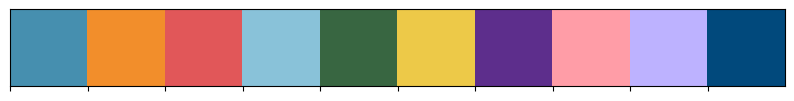

In [2]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
import numpy as np

palette = [
    "#468faf",  # blue
    "#F28E2B",  # orange
    "#E15759",  # red
    "#89c2d9",  # teal
    "#386641",  # green
    "#EDC948",  # yellow
    "#5d2e8c",  # purple
    "#FF9DA7",  # pink
    "#bdb2ff",  # lavender
    "#01497c",  # dark blue
    "#a7c957",  # light green
    "#D37295"   # magenta
]

K = 10

palette = palette[:K]
cmap = ListedColormap(palette)
norm = BoundaryNorm(np.arange(K + 1) - 0.5, K)

sns.palplot(palette)

## Exploration on simulated data

In [70]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr
from captum.attr import IntegratedGradients

torch.set_num_threads(1)

def generate_data(n=2000, p=20, seed=42):
    rng = np.random.default_rng(seed)

    X = rng.normal(size=(n, p)).astype(np.float32)

    Z = np.column_stack([
        X[:, 0] + 0.5 * X[:, 1]**2,
        np.sin(X[:, 1]) + X[:, 2]
    ]).astype(np.float32)

    return X, Z


X, Z = generate_data(n=2000, p=20)

X_tr, X_te, Z_tr, Z_te = train_test_split(
    X, Z, test_size=0.3, random_state=42
)

In [ ]:
plt.scatter(X[:, 0])

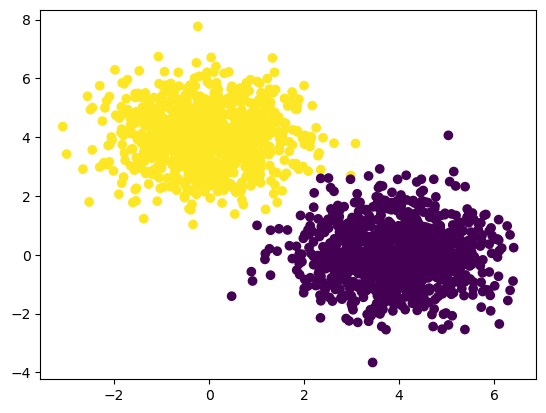

In [88]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr
from captum.attr import IntegratedGradients

torch.set_num_threads(1)

def sample_gmm(means: np.ndarray, covariances: np.ndarray, weights: np.ndarray, n_samples: int, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Sample observations and latent component labels from a GMM."""
    rng = np.random.default_rng(seed)
    labels = rng.choice(len(weights), size=n_samples, p=weights)
    observations = np.empty((n_samples, means.shape[1]), dtype=float)
    for component in range(len(weights)):
        index = np.flatnonzero(labels == component)
        if index.size:
            observations[index] = rng.multivariate_normal(means[component], covariances[component], size=index.size)
    return observations, labels
alpha = 4
means = np.array([[1, 0, 0], [0, 1, 0]])
weights = np.array([0.5, 0.5])
cov = np.array([np.eye(3) for i in range(2)])
X, labels = sample_gmm(means=alpha * means, covariances=cov, weights=weights, n_samples=2000, seed=7)

X_tr, X_te, labels_tr, labels_te = train_test_split(
    X, labels, test_size=0.3, random_state=42
)
plt.scatter(X[:,0], X[:, 1], c=labels)

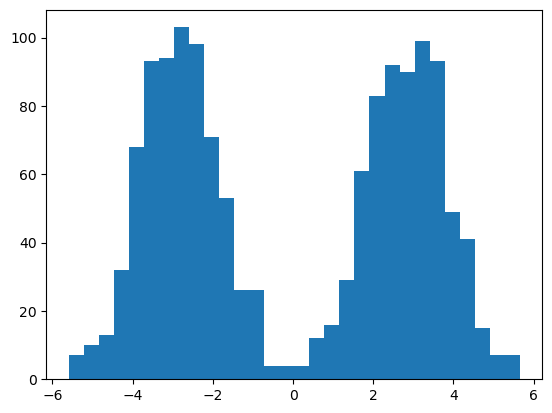

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
Z_tr = pca.fit_transform(X_tr)
plt.show()
plt.hist(Z_tr[:, 0], bins=30)
plt.show()


In [155]:
Z_te = pca.transform(X_te)

In [147]:
class Encoder(nn.Module):
    def __init__(self, p, d=1, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(p, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, d)
        )

    def forward(self, x):
        return self.net(x)

In [148]:
def train_encoder(X_tr, Z_tr, seed=0, hidden=64, epochs=500, lr=1e-3):
    torch.manual_seed(seed)
    model = Encoder(
        p=X_tr.shape[1],
        d=Z_tr.shape[1],
        hidden=hidden
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X_tensor = torch.tensor(X_tr.astype(np.float32))
    Z_tensor = torch.tensor(Z_tr.astype(np.float32))
    model.train()

    for epoch in range(epochs):
        optimizer.zero_grad()
        pred = model(X_tensor)
        loss = nn.functional.mse_loss(pred, Z_tensor)
        loss.backward()
        optimizer.step()
    model.eval()
    return model

In [149]:
X_tr.shape, Z_tr.shape

((1400, 3), (1400, 2))

In [150]:
B = 1
models = [train_encoder(X_tr, Z_tr, seed=b) for b in range(B)]

In [194]:
models[0]

Encoder(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

In [156]:
def distillation_mse(model, X, Z):
    with torch.no_grad():
        pred = model(torch.tensor(X.astype(np.float32))).numpy()
    return np.mean((pred - Z.astype(np.float32))**2)


fidelity_df = pd.DataFrame([
    {"seed": b,
    "train_mse": distillation_mse(model, X_tr, Z_tr),
    "test_mse": distillation_mse(model, X_te, Z_te)
    }
    for b, model in enumerate(models)
])

print(fidelity_df.describe())

       seed  train_mse  test_mse
count   1.0   1.000000  1.000000
mean    0.0   0.000431  0.000485
std     NaN        NaN       NaN
min     0.0   0.000431  0.000485
25%     0.0   0.000431  0.000485
50%     0.0   0.000431  0.000485
75%     0.0   0.000431  0.000485
max     0.0   0.000431  0.000485


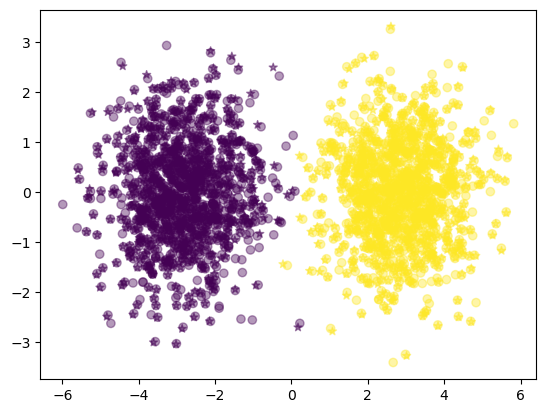

In [167]:
pred = models[0](torch.tensor(X.astype(np.float32))).detach().numpy()
plt.scatter(pred[:, 0], pred[:, 1], c=labels, alpha=0.4)
plt.scatter(Z_tr[:, 0], Z_tr[:, 1], c=labels_tr, alpha=0.5, marker='*')

In [168]:
def compute_ig(model, X, baseline=None, n_steps=100):
    X_tensor = torch.tensor(X, dtype=torch.float32)
    if baseline is None:
        baseline = torch.zeros_like(X_tensor)
    else:
        baseline = torch.tensor(baseline, dtype=torch.float32).expand_as(X_tensor)
    ig = IntegratedGradients(model)
    attrs = []

    for c in range(2):
        attr = ig.attribute(
            X_tensor,
            baselines=baseline,
            target=c,
            n_steps=n_steps
        )
        attrs.append(attr.detach().numpy())
    return np.stack(attrs, axis=1)

In [170]:
X_eval = X_te
compute_ig(models[0], X_eval)

print(attributions.shape)
# (B, n_eval, d, p)

(600, 2, 3)


<BarContainer object of 3 artists>

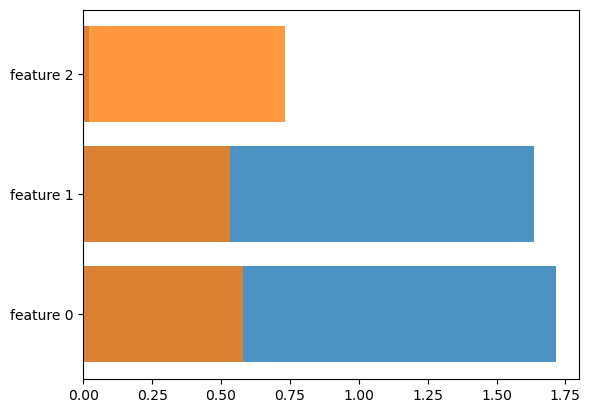

In [177]:
plt.barh([f'feature {i}' for i in np.arange(3)], np.mean(np.abs(attributions), axis=(0))[0], alpha=0.8)
plt.barh([f'feature {i}' for i in np.arange(3)], np.mean(np.abs(attributions), axis=(0))[1],alpha=0.8)

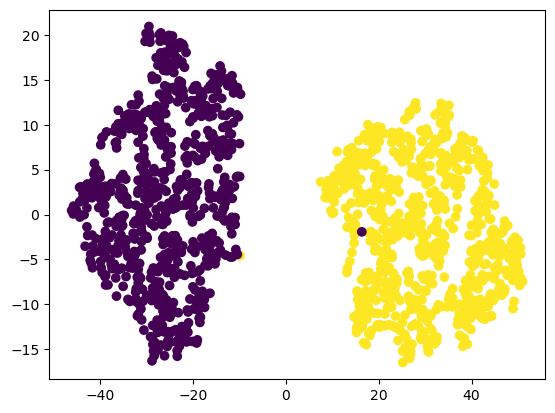

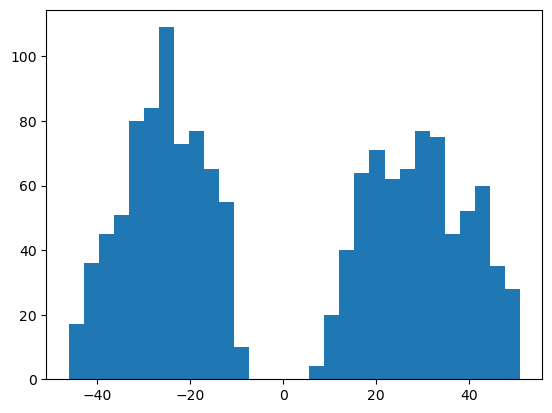

In [182]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=50)
Z_tr = tsne.fit_transform(X_tr)
plt.scatter(Z_tr[:, 0], Z_tr[:, 1], c=labels_tr)
plt.show()
plt.hist(Z_tr[:, 0], bins=30)
plt.show()


In [185]:
models = [train_encoder(X_tr, Z_tr, seed=b) for b in range(B)]
fidelity_df = pd.DataFrame([
    {"seed": b,
    "train_mse": distillation_mse(model, X_tr, Z_tr),
    "test_mse": distillation_mse(model, X_te, Z_te)
    }
    for b, model in enumerate(models)
])

print(fidelity_df.describe())

       seed  train_mse   test_mse
count   1.0    1.00000    1.00000
mean    0.0   13.56185  353.37326
std     NaN        NaN        NaN
min     0.0   13.56185  353.37326
25%     0.0   13.56185  353.37326
50%     0.0   13.56185  353.37326
75%     0.0   13.56185  353.37326
max     0.0   13.56185  353.37326


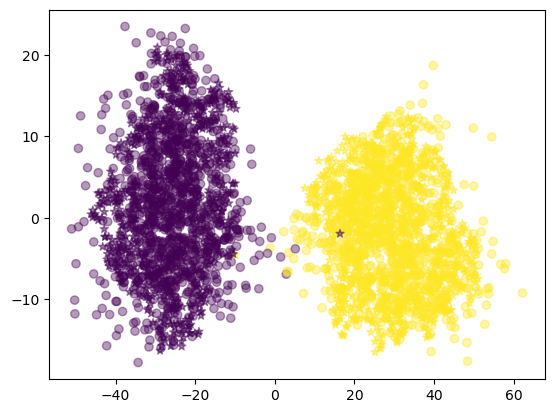

In [186]:
pred = models[0](torch.tensor(X.astype(np.float32))).detach().numpy()
plt.scatter(pred[:, 0], pred[:, 1], c=labels, alpha=0.4)
plt.scatter(Z_tr[:, 0], Z_tr[:, 1], c=labels_tr, alpha=0.5, marker='*')

In [187]:
X_eval = X_te
compute_ig(models[0], X_eval)

print(attributions.shape)
# (B, n_eval, d, p)

(600, 2, 3)


<BarContainer object of 3 artists>

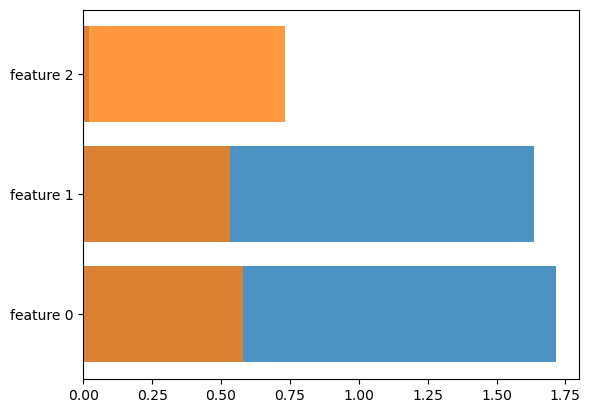

In [188]:
plt.barh([f'feature {i}' for i in np.arange(3)], np.mean(np.abs(attributions), axis=(0))[0], alpha=0.8)
plt.barh([f'feature {i}' for i in np.arange(3)], np.mean(np.abs(attributions), axis=(0))[1],alpha=0.8)

In [207]:
import numpy as np
from scipy.interpolate import CubicSpline

rng = np.random.default_rng(42)
n = 500

def sample_mixture(n):
    labels = rng.choice([-1, 1], size=n)
    signal = 2 * labels + rng.normal(scale=0.4, size=n)
    noise = rng.normal(size=n)
    return np.column_stack([signal, noise]), labels

X_train, labels_train = sample_mixture(n)
X_test, labels_test = sample_mixture(5000)

# Teacher: population PCA coordinate, with its sign fixed.
Z_train = X_train[:, 0]
Z_test = X_test[:, 0]

# Interpolate every training target using ONLY the noise feature.
# Include the zero baseline explicitly.
knots = np.r_[0.0, X_train[:, 1]]
targets = np.r_[0.0, Z_train]
order = np.argsort(knots)

assert np.all(np.diff(knots[order]) > 0)

q = CubicSpline(knots[order], targets[order])

def encoder1(X):
    return X[:, 0]

def encoder2(X):
    return q(X[:, 1])

# Exact IG formulas; no numerical integration is necessary.
def ig1(X):
    return np.column_stack([X[:, 0], np.zeros(len(X))])

def ig2(X):
    return np.column_stack([
        np.zeros(len(X)),
        q(X[:, 1]) - q(0.0),
    ])

for name, encoder in [
    ("Signal encoder", encoder1),
    ("Noise-interpolating encoder", encoder2),
]:
    train_mse = np.mean((encoder(X_train) - Z_train)**2)
    test_mse = np.mean((encoder(X_test) - Z_test)**2)
    print(f"{name}:")
    print(f"  Training distillation MSE: {train_mse:.6g}")
    print(f"  Test distillation MSE:     {test_mse:.6g}")

A = ig1(X_train)
B = ig2(X_train)

np.testing.assert_allclose(encoder2(X_train), Z_train, atol=1e-8)
np.testing.assert_allclose(B[:, 1], Z_train, atol=1e-8)

cosine = (A * B).sum(axis=1) / (
    np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1)
)
print("Mean training IG cosine:", cosine.mean())  # 0

Signal encoder:
  Training distillation MSE: 0
  Test distillation MSE:     0
Noise-interpolating encoder:
  Training distillation MSE: 8.87469e-34
  Test distillation MSE:     1322.15
Mean training IG cosine: 0.0


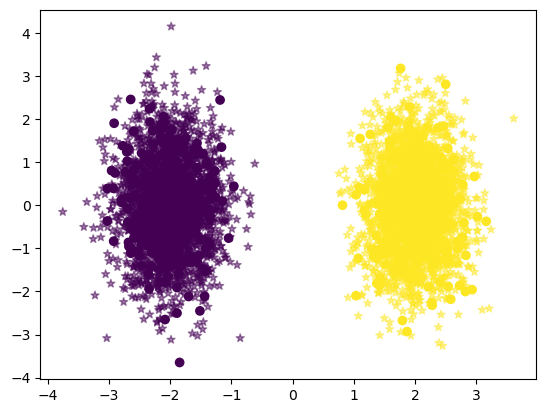

In [213]:
plt.scatter(X_train[:,0], X_train[:,1], c=labels_train)
plt.scatter(X_test[:,0], X_test[:,1], c=labels_test, marker='*', alpha=0.5)

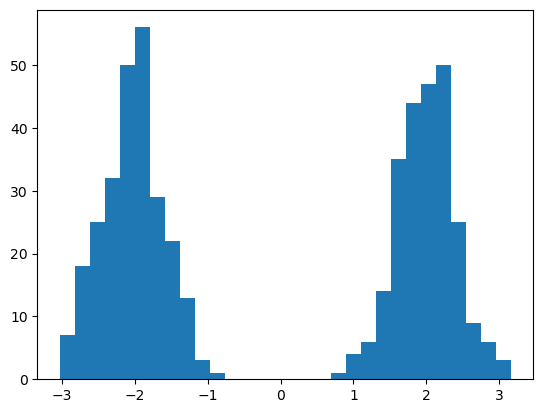

In [ ]:
plt.hist(Z_train, bins=30)
plt.show()

In [208]:
def encoder1(X):
    return X[:, 0]

def encoder2(X):
    return q(X[:, 1])

for name, encoder in [
    ("Signal encoder", encoder1),
    ("Noise-interpolating encoder", encoder2),
]:
    print(name)
    print("  Training MSE:",
          np.mean((encoder(X_train) - Z_train)**2))
    print("  Test MSE:",
          np.mean((encoder(X_test) - Z_test)**2))

# Exact zero-baseline IG, shape (samples, input_features).
A = np.column_stack([
    X_train[:, 0],
    np.zeros(len(X_train)),
])
B = np.column_stack([
    np.zeros(len(X_train)),
    q(X_train[:, 1]) - q(0.0),
])

np.testing.assert_allclose(encoder2(X_train), Z_train, atol=1e-8)
np.testing.assert_allclose(B[:, 1], Z_train, atol=1e-8)

cosine = (A * B).sum(axis=1) / (
    np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1)
)
print("Mean training IG cosine:", cosine.mean())

Signal encoder
  Training MSE: 0.0
  Test MSE: 0.0
Noise-interpolating encoder
  Training MSE: 8.874685183736382e-34
  Test MSE: 1322.1504197170411
Mean training IG cosine: 0.0


In [209]:
import torch
from torch import nn
from captum.attr import IntegratedGradients

class SignalEncoder(nn.Module):
    def forward(self, X):
        return X[:, 0]  # Preserve the gradient graph.


class SplineEncoder(nn.Module):
    def __init__(self, scipy_spline):
        super().__init__()
        self.register_buffer(
            "knots",
            torch.tensor(scipy_spline.x.copy(), dtype=torch.float64),
        )
        self.register_buffer(
            "coefficients",
            torch.tensor(scipy_spline.c.copy(), dtype=torch.float64),
        )

    def forward(self, X):
        v = X[:, 1].contiguous()

        # Identify the cubic polynomial for each input value.
        interval = torch.searchsorted(self.knots, v, right=True) - 1
        interval = interval.clamp(0, self.knots.numel() - 2)

        offset = v - self.knots[interval]
        c = self.coefficients[:, interval]

        # Same piecewise cubic as SciPy, evaluated through autograd.
        return ((c[0] * offset + c[1]) * offset + c[2]) * offset + c[3]


signal_encoder = SignalEncoder().double().eval()
spline_encoder = SplineEncoder(q).eval()

inputs = torch.as_tensor(X_train, dtype=torch.float64)

# Verify that the PyTorch spline reproduces the SciPy spline.
with torch.no_grad():
    np.testing.assert_allclose(
        spline_encoder(inputs).numpy(),
        q(X_train[:, 1]),
        rtol=1e-9,
        atol=1e-8,
    )


def compute_scalar_ig(model, inputs, n_steps=2000):
    ig = IntegratedGradients(model)

    attr, delta = ig.attribute(
        inputs,
        baselines=torch.zeros_like(inputs),
        target=None,                  # Scalar output per observation.
        n_steps=n_steps,
        internal_batch_size=2 * len(inputs),
        return_convergence_delta=True,
    )

    return attr.detach().numpy(), delta.detach().numpy()


A, delta_A = compute_scalar_ig(signal_encoder, inputs)
B, delta_B = compute_scalar_ig(spline_encoder, inputs)

print("Attribution shapes:", A.shape, B.shape)  # (500, 2)
print("Signal encoder mean |delta|:", np.abs(delta_A).mean())
print("Spline encoder mean |delta|:", np.abs(delta_B).mean())
print("Spline encoder max |delta|:", np.abs(delta_B).max())

denominator = np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1)
cosine = np.divide(
    (A * B).sum(axis=1),
    denominator,
    out=np.full(len(A), np.nan),
    where=denominator > 0,
)
print("Mean computed IG cosine:", np.nanmean(cosine))

Attribution shapes: (500, 2) (500, 2)
Signal encoder mean |delta|: 1.1680272971048567e-11
Spline encoder mean |delta|: 6.217443340287224
Spline encoder max |delta|: 88.3499615408974
Mean computed IG cosine: 0.0


In [210]:
print("Signal IG maximum error:",
      np.max(np.abs(A[:, 0] - Z_train)))

print("Spline IG maximum error:",
      np.max(np.abs(B[:, 1] - Z_train)))

Signal IG maximum error: 1.8329782136561334e-11
Spline IG maximum error: 88.3499615408974


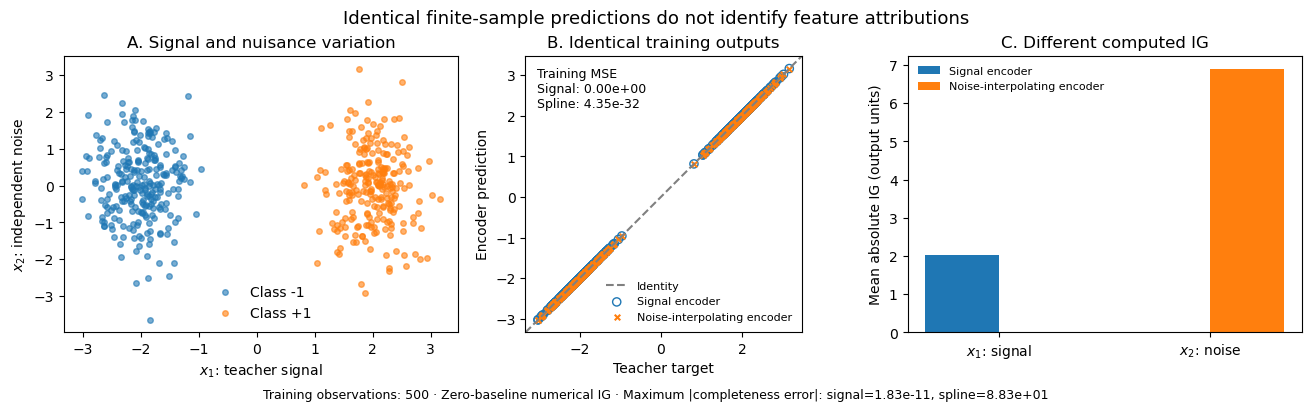

In [218]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Predictions from the same models used for computed IG.
inputs = torch.as_tensor(X_train, dtype=torch.float64)

with torch.no_grad():
    pred_signal = signal_encoder(inputs).cpu().numpy()
    pred_spline = spline_encoder(inputs).cpu().numpy()

A = np.asarray(A)
B = np.asarray(B)
assert A.shape == B.shape == X_train.shape

mse_signal = np.mean((pred_signal - Z_train)**2)
mse_spline = np.mean((pred_spline - Z_train)**2)

mean_abs_ig = np.stack([
    np.abs(A).mean(axis=0),
    np.abs(B).mean(axis=0),
])

colors = ["tab:blue", "tab:orange"]
fig, axes = plt.subplots(
    1, 3, figsize=(13, 4), layout="constrained"
)

# A. Data distribution.
ax = axes[0]
for label, color in zip([-1, 1], colors):
    mask = labels_train == label
    ax.scatter(
        X_train[mask, 0], X_train[mask, 1],
        s=16, alpha=0.6, color=color,
        label=f"Class {label:+d}",
    )

ax.set(
    title="A. Signal and nuisance variation",
    xlabel=r"$x_1$: teacher signal",
    ylabel=r"$x_2$: independent noise",
)
ax.legend(frameon=False)

# B. Matching training predictions.
ax = axes[1]
bounds = [
    min(Z_train.min(), pred_signal.min(), pred_spline.min()),
    max(Z_train.max(), pred_signal.max(), pred_spline.max()),
]
padding = 0.05 * max(bounds[1] - bounds[0], 1e-12)
bounds = [bounds[0] - padding, bounds[1] + padding]

ax.plot(bounds, bounds, "--", color="0.5", label="Identity")
ax.scatter(
    Z_train, pred_signal,
    s=35, facecolors="none", edgecolors=colors[0],
    label="Signal encoder",
)
ax.scatter(
    Z_train, pred_spline,
    s=16, marker="x", color=colors[1],
    label="Noise-interpolating encoder",
)
ax.set(
    title="B. Identical training outputs",
    xlabel="Teacher target",
    ylabel="Encoder prediction",
    xlim=bounds,
    ylim=bounds,
)
ax.set_aspect("equal", adjustable="box")
ax.text(
    0.04, 0.96,
    f"Training MSE\n"
    f"Signal: {mse_signal:.2e}\n"
    f"Spline: {mse_spline:.2e}",
    transform=ax.transAxes, va="top", fontsize=9,
)
ax.legend(loc="lower right", frameon=False, fontsize=8)

# C. Different computed feature attributions.
ax = axes[2]
positions = np.arange(2)
width = 0.35

ax.bar(
    positions - width / 2, mean_abs_ig[0],
    width, color=colors[0], label="Signal encoder",
)
ax.bar(
    positions + width / 2, mean_abs_ig[1],
    width, color=colors[1], label="Noise-interpolating encoder",
)
ax.set_xticks(
    positions,
    [r"$x_1$: signal", r"$x_2$: noise"],
)
ax.set(
    title="C. Different computed IG",
    ylabel="Mean absolute IG (output units)",
)
ax.legend(frameon=False, fontsize=8)

max_delta_signal = np.max(np.abs(delta_A))
max_delta_spline = np.max(np.abs(delta_B))

fig.suptitle(
    "Identical finite-sample predictions do not identify feature attributions",
    fontsize=13,
)
fig.supxlabel(
    f"Training observations: {len(X_train)} · Zero-baseline numerical IG · "
    f"Maximum |completeness error|: "
    f"signal={max_delta_signal:.2e}, spline={max_delta_spline:.2e}",
    fontsize=9,
)

# Save before displaying.
fig.savefig("distillation_attribution_ambiguity.pdf", bbox_inches="tight")
fig.savefig(
    "distillation_attribution_ambiguity.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

## Exploration on baby MNIST

### MEDAL encoder

In [6]:
from sklearn.datasets import load_digits 

data = load_digits()
X, y = data['data'], data['target']

In [ ]:
# # 1. Find the best autoencoder architecture for your data
# result = medal.tune_medal_architecture(
#     X_train,
#     teacher="tsne",
#     teacher_params={"perplexity": 30},
#     output_dir="experiments/arch_search",
# )
# arch_config = {
#     "hidden_dims": [512, 512],
#     "latent_dim": 2,
#     "activation": "SELU",
#     "use_batchnorm": False,
#     "dropout_rate": 0.0,
#     "lr": 0.01,
#     "lambda_d": 5000,
#     "max_epochs": 3000,
#     "batch_size": 256,
# }

# # 2. Sweep teacher hyperparameters, training one student per setting
# sweep_results = medal.run_teacher_sweep(
#     X_train,
#     output_dir="experiments/sweep",
#     teacher="tsne",
#     arch_config=arch_config,
# )

# # 3. Evaluate and select the optimal hyperparameter
# df = sweep_results.load_metrics(X_test)
# opt_param = medal.select_teacher_param(df, param_col="perplexity")
# print(f"Optimal perplexity: {opt_param}")

# # 4. Visualise reconstruction error across the sweep
# medal.plot_reconstruction_error(df, opt_param, param_col="perplexity")

(_arch_search_trainable pid=7252) Exception ignored in: <function WeakSet.__init__.<locals>._remove at 0x1015bcd30>
(_arch_search_trainable pid=7252) Traceback (most recent call last):
(_arch_search_trainable pid=7252)   File "/Users/clairehe/anaconda3/envs/medal_env/lib/python3.10/_weakrefset.py", line 39, in _remove
(_arch_search_trainable pid=7252)     def _remove(item, selfref=ref(self)):
(_arch_search_trainable pid=7252)   File "/Users/clairehe/anaconda3/envs/medal_env/lib/python3.10/site-packages/ray/_private/worker.py", line 1060, in sigterm_handler
(_arch_search_trainable pid=7252)     raise_sys_exit_with_custom_error_message(
(_arch_search_trainable pid=7252)   File "python/ray/_raylet.pyx", line 714, in ray._raylet.raise_sys_exit_with_custom_error_message
(_arch_search_trainable pid=7252) SystemExit: 1
NaN or Inf found in input tensor.
NaN or Inf found in input tensor.
NaN or Inf found in input tensor.
NaN or Inf found in input tensor.
NaN or Inf found in input tensor.
NaN or

Retrained using the saved winning architecture on the saved 1,149-row training split. Inputs retain their original 0–16 pixel scale. Attribution uses the 288-row validation split, a zero baseline, and 100 integration steps. These are sklearn 8×8 digits. 


In [7]:
# Load data 
from pathlib import Path
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import medal
OUT = Path('../data/baby_mnist_medal')
cfg = json.loads((OUT / 'config.json').read_text())
model = medal.load_model(OUT / 'baby_mnist_ckpts/final.pt', input_dim=64, hidden_dims=tuple(cfg['hidden_dims']), latent_dim=2, activation=cfg['activation'], use_batchnorm=cfg['use_batchnorm'], dropout_rate=cfg['dropout_rate'])
model.eval()
metrics = json.loads((OUT / 'metrics.json').read_text())
metrics

{'train_distill_mse': 5.551977210416226e-06,
 'train_recon_mse': 5.482367992401123,
 'validation_recon_mse': 7.970141887664795,
 'validation_mean_baseline_mse': 18.84552764892578,
 'ig_mean_abs_completeness_error': 0.013104701414704323,
 'ig_max_abs_completeness_error': 0.05866670608520508}

In [8]:
import numpy as np
from sklearn.datasets import load_digits
from pathlib import Path

folder = Path("/Users/clairehe/Documents/GitHub/MEDAL_FI/encoder_FI/experiments/arch_search")
X_train = np.load(folder / "X_train.npy")
X_val = np.load(folder / 'X_val.npy')
Z = np.load( folder / "embeddings/arch_search_teacher.npy")
digits = load_digits()
label_lookup = {tuple(image): label for image, label in zip(digits.data, digits.target)}
y_train = np.array([label_lookup[tuple(image)] for image in X_train])

In [50]:
plot_df = pd.DataFrame(Z, columns=['tsne_1', 'tsne_2'])
plot_df['labels_codes'] = y_train
plot_df['labels'] = [f'Digit {i}' for i in y_train]
plot_df.head()

,tsne_1,tsne_2,labels_codes,labels
0,-21.326470,-7.677235,9,Digit 9
1,-29.475782,28.902877,2,Digit 2
2,-19.232154,-9.276630,9,Digit 9
3,30.392389,-14.896543,6,Digit 6
4,-1.314377,21.238024,1,Digit 1


In [83]:
y_train

array([9, 2, 9, ..., 8, 4, 8], shape=(1149,))

Text(0.5, 1.0, 'Teacher t-SNE')

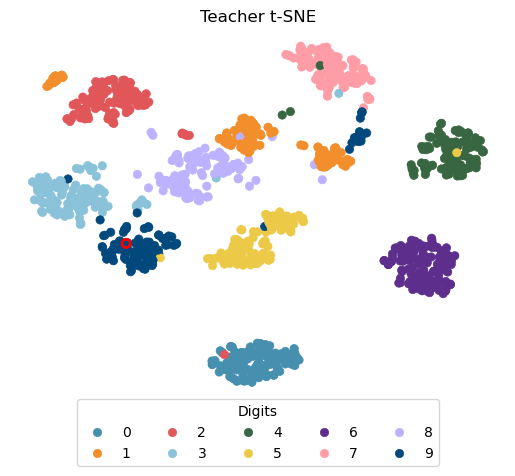

In [82]:
from matplotlib.patches import Patch
sns.scatterplot(plot_df,
                x='tsne_1', 
                y='tsne_2', 
                hue='labels_codes',
                palette=palette, 
                legend=True,
                edgecolor=None
                )
sns.scatterplot(plot_df.iloc[[0]], x='tsne_1', y='tsne_2',  facecolor='none', edgecolor='red', linewidth=2)
plt.legend(title="Digits" \
"", loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=5)

plt.axis('off')
plt.title("Teacher t-SNE")


(np.float64(-40.08837167312631),
 np.float64(40.02774637732219),
 np.float64(-48.50689382246786),
 np.float64(48.493135090309465))

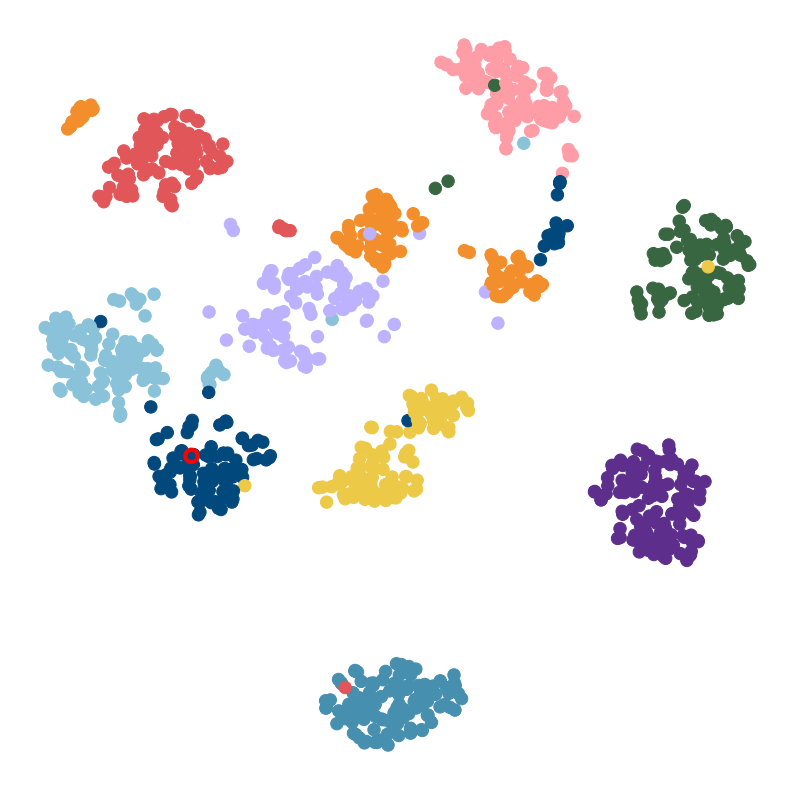

In [99]:
plt.figure(figsize=(10, 10))
sns.scatterplot(plot_df,
                x='tsne_1', 
                y='tsne_2', 
                hue='labels_codes',
                palette=palette, 
                legend=False,
                s=80,
                edgecolor=None
                )
sns.scatterplot(plot_df.iloc[[0]], x='tsne_1', y='tsne_2',  facecolor='none', edgecolor='red', linewidth=3, s=80)
plt.axis('off')
# plt.title("Teacher t-SNE embedding (train)")


Attribution shape: (288, 2, 64)


(np.float64(-0.5), np.float64(2699.5), np.float64(719.5), np.float64(-0.5))

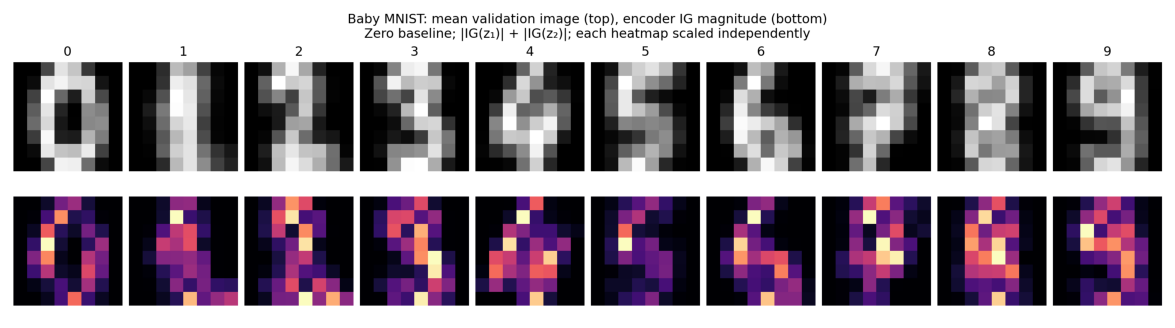

In [88]:
data = np.load(OUT / 'encoder_ig.npz')
X_val = data['X']
y_val = data['labels']
attributions = data['attributions']  # (samples, 2 latent coordinates, 64 pixels)
importance = np.abs(attributions).sum(axis=1)
print('Attribution shape:', attributions.shape)
plt.figure(figsize=(15, 4))
plt.imshow(plt.imread(OUT / 'encoder_ig.png'))
plt.axis('off')

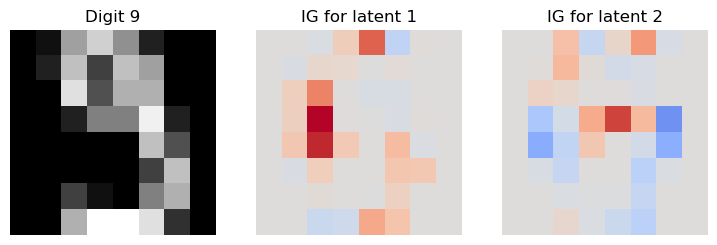

In [86]:
# Inspect a validation example and signed attribution for each coordinate.
i = 0
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(X_train[i].reshape(8,8), cmap='gray')
axes[0].set_title(f'Digit {y_train[i]}')
limit = np.abs(attributions[i]).max()
for j in range(2):
    axes[j+1].imshow(attributions[i,j].reshape(8,8), cmap='coolwarm', vmin=-limit, vmax=limit)
    axes[j+1].set_title(f'IG for latent {j+1}')
for ax in axes: ax.axis('off')
plt.show()

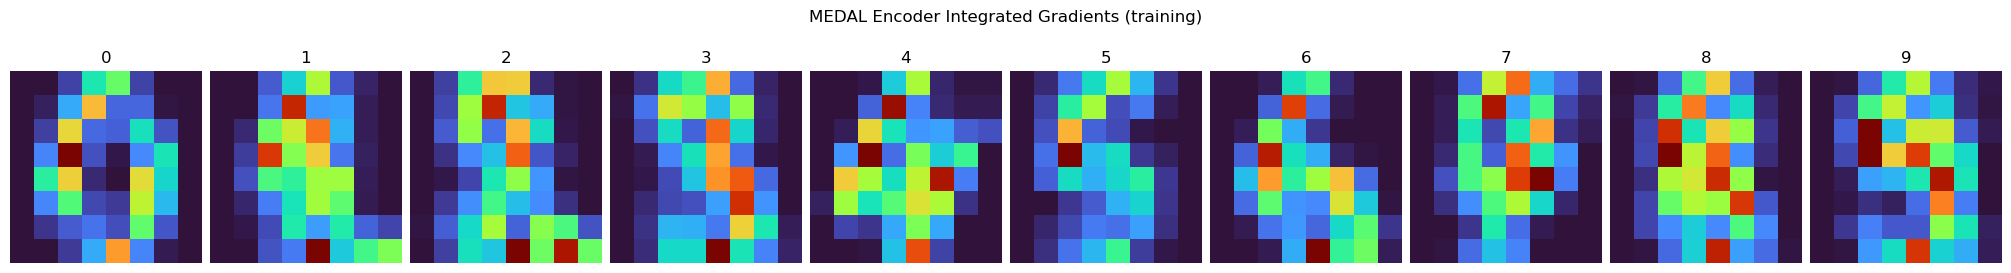

In [109]:
# Adapted from benchmarking/feature_attribution.ipynb: L2 across latent coordinates.
l2_importance = np.linalg.norm(attr, axis=1)
fig, axes = plt.subplots(1, 10, figsize=(20, 3), layout='constrained')
for digit, ax in enumerate(axes.flat):
    values = l2_importance[y_train == digit].mean(axis=0)
    values = values / max(values.sum(), np.finfo(float).eps)
    ax.imshow(values.reshape(8, 8), cmap='turbo', vmin=0)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('MEDAL Encoder Integrated Gradients (training)')
plt.show()


In [11]:
from captum.attr import IntegratedGradients
X_train = X_train.astype('float32')
# Attribute both normalized latent coordinates on held-out input rows.
ig = IntegratedGradients(model.encoder)
attrs=[]
deltas=[]
for j in range(2):
    aa=[] 
    dd=[]
    for start in range(0, len(X_train), 32):
       t = torch.from_numpy(X_train[start:start+32])
       a, d = ig.attribute(t, 
                           baselines=torch.zeros_like(t),
                           target=j,
                           n_steps=100,
                           internal_batch_size=128,
                           return_convergence_delta=True)
       aa.append(a.detach().numpy())
       dd.append(d.detach().numpy())
    attrs.append(np.concatenate(aa))
    deltas.append(np.concatenate(dd))

medal_train_ig = np.stack(attrs,axis=1)
delta = np.stack(deltas,axis=1)
assert np.isfinite(attr).all()

NameError: name 'attr' is not defined

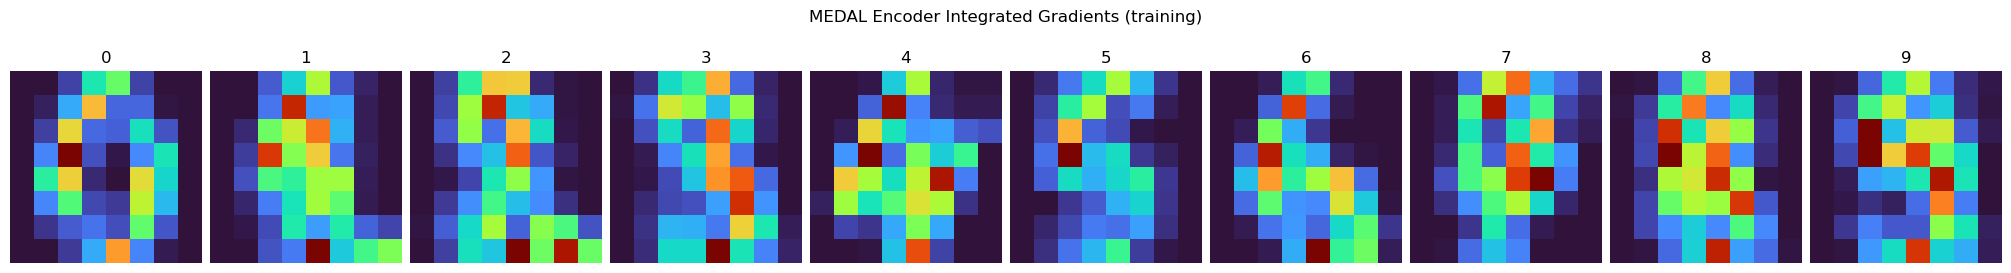

In [108]:
# Adapted from benchmarking/feature_attribution.ipynb: L2 across latent coordinates.
l2_importance = np.linalg.norm(attr, axis=1)
fig, axes = plt.subplots(1, 10, figsize=(20, 3), layout='constrained')
for digit, ax in enumerate(axes.flat):
    values = l2_importance[y_train == digit].mean(axis=0)
    values = values / max(values.sum(), np.finfo(float).eps)
    ax.imshow(values.reshape(8, 8), cmap='turbo', vmin=0)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('MEDAL Encoder Integrated Gradients (training)')
plt.show()


### Comparisons (external methods)

In [6]:
import sys
sys.path.append("../")
from benchmarking.grad_exp import *
from benchmarking.limeade import LIMEADE
from benchmarking.lxdr import LXDR 


In [9]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, method='exact')

#### LIMEADE

In [83]:
# Apply LIMEADE

lm = LIMEADE(data=X_train, reduced_data=Z, fit_intercept=True)
V = lm.fit(level='local', gamma=0.01)
print(V.shape)

(1149, 64, 2)


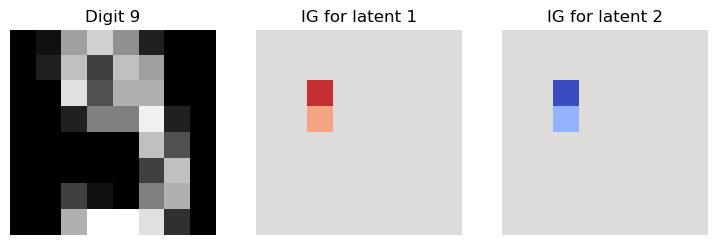

In [84]:
# Inspect a training example and signed attribution for each coordinate.
i = 0
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(X_train[i].reshape(8,8), cmap='gray')
axes[0].set_title(f'Digit {y_train[i]}')
limit = np.abs(V[i]).max()
for j in range(2):
    axes[j+1].imshow(V[i,:,j].reshape(8,8), cmap='coolwarm', vmin=-limit, vmax=limit)
    axes[j+1].set_title(f'IG for latent {j+1}')
for ax in axes: ax.axis('off')
plt.show()

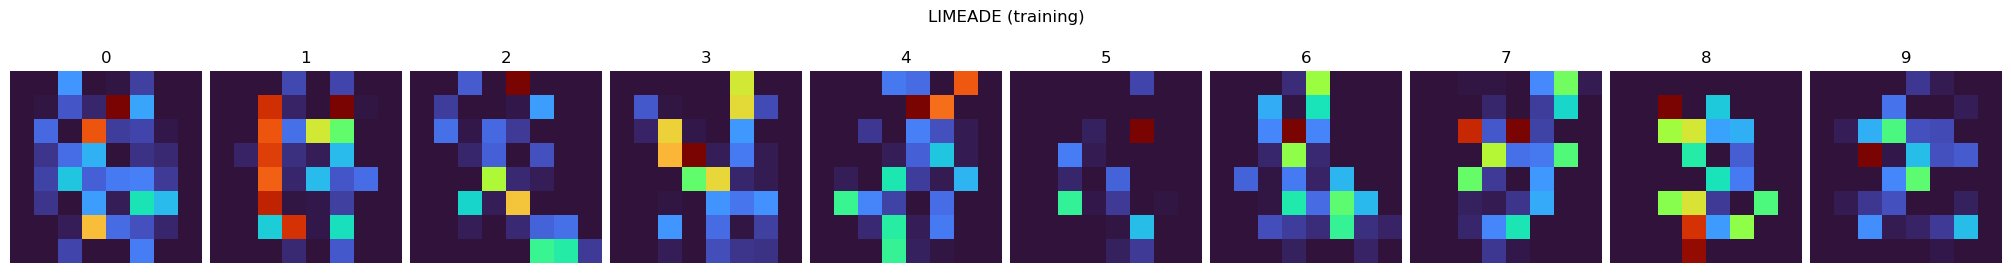

In [ ]:
l2_importance = np.linalg.norm(V, axis=2)
fig, axes = plt.subplots(1, 10, figsize=(20, 3), layout='constrained')
for digit, ax in enumerate(axes.flat):
    values = l2_importance[y_train == digit].mean(axis=0)
    values = values / max(values.sum(), np.finfo(float).eps)
    ax.imshow(values.reshape(8, 8), cmap='turbo', vmin=0)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('LIMEADE (training)')
plt.show()


#### Gradient (tSNE)
Uses a modified t-SNE...

In [100]:
import sys
sys.path.append('../')
from benchmarking._t_sne import TSNE
from benchmarking.grad_exp import *
tsne = TSNE(n_components=2, perplexity=30, random_state=42, method='exact')
feat=tsne.fit_transform(X_train)
import tqdm
idx= 0
direct_2order=calc_direct_2order(tsne, feat, idx)
cross_2order_tot=cross_2order_total(tsne, X_train, feat, idx)
grad_x=grad_wtr_x(direct_2order, cross_2order_tot)
l2 = np.sqrt((grad_x[0])**2 + (grad_x[1]**2))


here


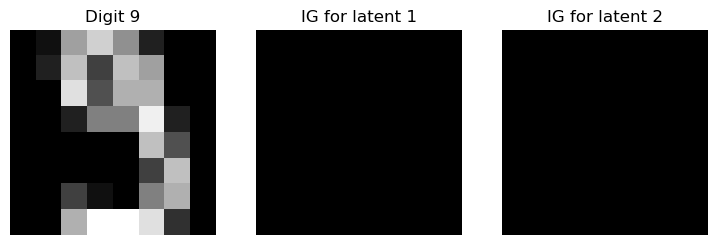

In [105]:
# Inspect a training example and signed attribution for each coordinate.
i = 0
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(X_train[i].reshape(8,8), cmap='gray')
axes[0].set_title(f'Digit {y_train[i]}')
limit = np.abs(l2[i]).max()
for j in range(2):
    axes[j+1].imshow(grad_x[j,:].reshape(8,8), cmap='grey', vmin=-limit, vmax=limit)
    axes[j+1].set_title(f'IG for latent {j+1}')
for ax in axes: ax.axis('off')
plt.show()

In [ ]:
l2

In [7]:
import pickle
with open('experiments/arch_search/comp_files/grad_exp.pkl', 'rb') as file:
    grad_expl = pickle.load(file)

In [11]:
grad_expl = np.array(grad_expl)

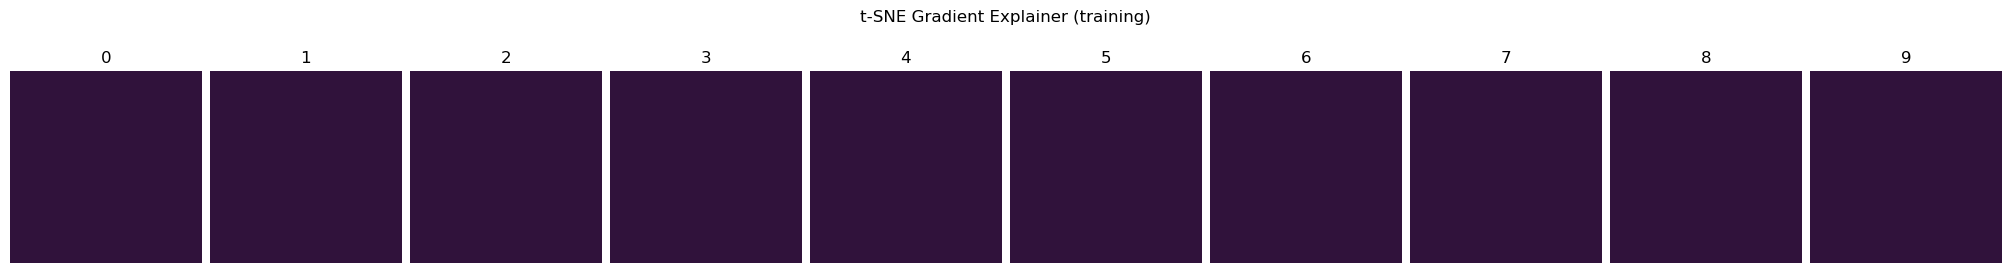

In [12]:
fig, axes = plt.subplots(1, 10, figsize=(20, 3), layout='constrained')
for digit, ax in enumerate(axes.flat):
    values = grad_expl[y_train == digit].mean(axis=0)
    values = values / max(values.sum(), np.finfo(float).eps)
    ax.imshow(values.reshape(8, 8), cmap='turbo', vmin=0)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('t-SNE Gradient Explainer (training)')
plt.show()

#### LXDR

In [12]:
# Not valid for tSNE

#### BIR


In [5]:
import numpy as np
from benchmarking.bir import generate_samples_SMOTE, query_blackbox_tsne

idx = 0
# Generate 100 perturbed images near training image idx.
x_samples = np.asarray(generate_samples_SMOTE(selected_id=idx, X=X_train, k_nearbors=10, n_samples=10)).reshape(-1, X_train.shape[1])

# Initialize new points near feat[idx], then optimize their positions
# while holding the original embedding points fixed.
np.random.seed(42)
y_samples = query_blackbox_tsne(
    X=X_train,
    Y=Z,
    query_idx=idx,
    query_points=x_samples,
    tsne_hyper_params={"n_components": 2, "perplexity": 30, "random_state": 42, "method": "exact",
        "max_iter": 300, "verbose": 1},
)

print(x_samples.shape)  # (100, number_of_pixels)
print(y_samples.shape)  # (100, 2)

ModuleNotFoundError: No module named 'benchmarking'

In [ ]:
from sklearn.linear_model import ElasticNet
from benchmarking.bir import explain_samples
## FOR FEATURE ATTRIBUTION PROBLEM ORIGINAL ONLY LOOKS AT TRAINING R2
W, r2, rotation = explain_samples(x_samples, y_samples, linear_model=ElasticNet())

In [20]:
W.shape

(2, 64)

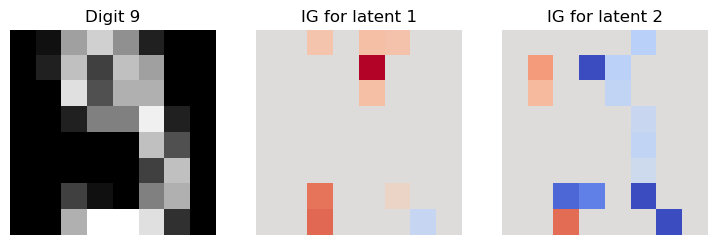

In [17]:
# Inspect a training example and signed attribution for each coordinate.
i = 0
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(X_train[i].reshape(8,8), cmap='gray')
axes[0].set_title(f'Digit {y_train[i]}')
limit = np.abs(W[i]).max()
for j in range(2):
    axes[j+1].imshow(W[j,:].reshape(8,8), cmap='coolwarm', vmin=-limit, vmax=limit)
    axes[j+1].set_title(f'IG for latent {j+1}')
for ax in axes: ax.axis('off')
plt.show()

In [13]:
# Load saved scores, computation takes 18h for full training split
import pickle
with open('experiments/arch_search/comp_files/bir_expl.pkl', 'rb') as file:
    BIR_attr = pickle.load(file)

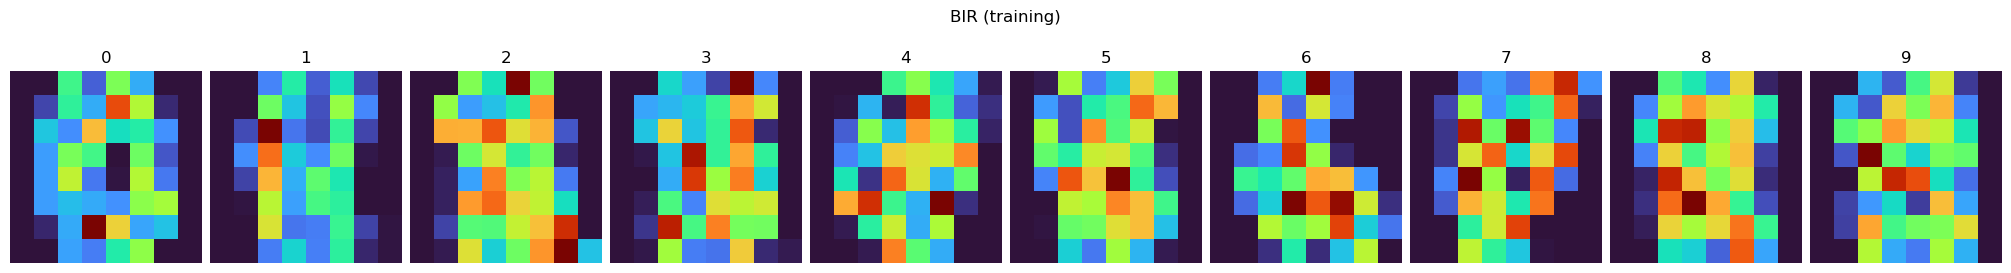

In [14]:
l2_importance = np.linalg.norm(BIR_attr, axis=1)
fig, axes = plt.subplots(1, 10, figsize=(20, 3), layout='constrained')
for digit, ax in enumerate(axes.flat):
    values = l2_importance[y_train == digit].mean(axis=0)
    values = values / max(values.sum(), np.finfo(float).eps)
    ax.imshow(values.reshape(8, 8), cmap='turbo', vmin=0)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('BIR (training)')
plt.show()


### Encoder-only distilled 

In [25]:
from pathlib import Path
from copy import deepcopy
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients
from medal.io import load_model

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(4)
from sklearn.datasets import load_digits

# Load data
folder = Path("/Users/clairehe/Documents/GitHub/MEDAL_FI/encoder_FI/experiments/arch_search")
X_train, X_val = np.load(folder / "X_train.npy").astype(np.float32), np.load(folder / 'X_val.npy').astype(np.float32)
X = torch.from_numpy(X_train)
V = torch.from_numpy(X_val)
teach_embed = np.load( folder / "embeddings/arch_search_teacher.npy").astype(np.float32)
Z = torch.from_numpy(teach_embed)
digits = load_digits()
label_lookup = {tuple(image): label for image, label in zip(digits.data, digits.target)}
labels = np.array([label_lookup[tuple(image)] for image in X_train])

# Load medal's encoder 
OUT = Path('../data/baby_mnist_medal')
cfg = json.loads((OUT / 'config.json').read_text())
model = medal.load_model(OUT / 'baby_mnist_ckpts/final.pt', input_dim=64, hidden_dims=tuple(cfg['hidden_dims']), latent_dim=2, activation=cfg['activation'], use_batchnorm=cfg['use_batchnorm'], dropout_rate=cfg['dropout_rate'])
model.eval()

# Copy architecture, then initialize fresh weights.
encoder = deepcopy(model.encoder)
for module in encoder.modules():
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()

loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(X, Z),
    batch_size=cfg["batch_size"],
    shuffle=True)

optimizer = torch.optim.AdamW(
    encoder.parameters(),
    lr=cfg["lr"],
    weight_decay=cfg["adamw_weight_decay"])

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    factor=cfg["t_factor"],
    patience=cfg["t_patience"],
    min_lr=cfg["eta_min"])

# Train ONLY with distillation loss; there is no decoder.
best_mse = float("inf")
best_state = None

for epoch in range(cfg["max_epochs"]):
    encoder.train()
    for xb, zb in loader:
        optimizer.zero_grad()
        loss = torch.nn.functional.mse_loss(encoder(xb), zb)
        loss.backward()
        optimizer.step()

    encoder.eval()
    with torch.no_grad():
        mse = torch.nn.functional.mse_loss(encoder(X), Z).item()

    scheduler.step(mse)
    if mse < best_mse:
        best_mse = mse
        best_state = deepcopy(encoder.state_dict())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}: distillation MSE = {mse:.8g}")

encoder.load_state_dict(best_state)
encoder.eval()

with torch.no_grad():
    medal_mse = torch.nn.functional.mse_loss(model.encoder(X), Z).item()

print(f"MEDAL training distillation MSE:        {medal_mse:.8g}")
print(f"Encoder-only training distillation MSE: {best_mse:.8g}")


def attribute(model, inputs, n_steps=2000):
    """Signed IG for each latent coordinate: (images, 2, 784)."""
    ig = IntegratedGradients(model)
    coordinates, errors = [], []

    for coordinate in range(2):
        attrs, deltas = [], []
        for batch in inputs.split(32):
            a, d = ig.attribute(
                batch,
                baselines=torch.zeros_like(batch),
                target=coordinate,
                n_steps=n_steps,
                internal_batch_size=128,
                return_convergence_delta=True,
            )
            attrs.append(a.detach().numpy())
            deltas.append(d.detach().numpy())

        coordinates.append(np.concatenate(attrs))
        errors.append(np.concatenate(deltas))

    return np.stack(coordinates, axis=1), np.stack(errors, axis=1)


# Recompute both using identical IG settings.
medal_ig, medal_delta = attribute(model.encoder, V)
encoder_ig, encoder_delta = attribute(encoder, V)
encoder_ig_train, encoder_delta_train = attribute(encoder, X)

print("Mean absolute IG completeness error:")
print(f"  MEDAL:        {np.abs(medal_delta).mean():.8g}")
print(f"  Encoder-only: {np.abs(encoder_delta).mean():.8g}")

# Compare signed attributions, preserving the two teacher coordinates.
a = medal_ig.reshape(len(V), -1)
b = encoder_ig.reshape(len(V), -1)
denominator = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
valid = denominator > 0
cosine = np.full(len(V), np.nan)
cosine[valid] = (a[valid] * b[valid]).sum(axis=1) / denominator[valid]
print(f"Mean signed IG cosine similarity: {np.nanmean(cosine):.4f}")

# Aggregate coordinate magnitudes for visual comparison.
medal_maps = np.abs(medal_ig).sum(axis=1)
encoder_maps = np.abs(encoder_ig).sum(axis=1)

root = Path('experiments/arch_search/comp_files')
torch.save(best_state, root / "encoder_only.pt")
np.savez_compressed(
    root / "medal_vs_encoder_ig.npz",
    labels=labels,
    medal_ig=medal_ig,
    encoder_ig=encoder_ig,
    encoder_train_ig=encoder_ig_train,
    medal_delta=medal_delta,
    encoder_delta=encoder_delta,
    signed_cosine=cosine,
)

Epoch 100: distillation MSE = 0.54736042
Epoch 200: distillation MSE = 0.17063613
Epoch 300: distillation MSE = 0.1466478
Epoch 400: distillation MSE = 0.020745171
Epoch 500: distillation MSE = 0.0069983201
Epoch 600: distillation MSE = 0.0021453626
Epoch 700: distillation MSE = 0.0010035619
Epoch 800: distillation MSE = 0.00054928509
Epoch 900: distillation MSE = 0.00032092087
Epoch 1000: distillation MSE = 0.00018275785
Epoch 1100: distillation MSE = 9.7248769e-05
Epoch 1200: distillation MSE = 7.6481476e-05
Epoch 1300: distillation MSE = 3.3586806e-05
Epoch 1400: distillation MSE = 2.8023664e-05
Epoch 1500: distillation MSE = 1.6481397e-05
Epoch 1600: distillation MSE = 1.2067128e-05
Epoch 1700: distillation MSE = 8.382026e-06
Epoch 1800: distillation MSE = 3.7582169e-05
Epoch 1900: distillation MSE = 5.0063404e-06
Epoch 2000: distillation MSE = 3.1700686e-06
Epoch 2100: distillation MSE = 1.75768e-06
Epoch 2200: distillation MSE = 9.4536341e-07
Epoch 2300: distillation MSE = 6.8666

In [10]:
# Load data 
from pathlib import Path
import json
import numpy as np
import torch
root= Path('experiments/arch_search/comp_files')

model = torch.load(root / 'encoder_only.pt')
attr_encoder = np.load(root / 'medal_vs_encoder_ig.npz')

/var/folders/r4/_v5hj9j14b53twvkrltmh9vh0000gn/T/ipykernel_53432/2329719552.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model = torch.load(root / 'encoder_only.pt')


In [13]:
attributions = attr_encoder['encoder_ig']

In [21]:
from captum.attr import IntegratedGradients
X_train = X_train.astype('float32')
# Attribute both normalized latent coordinates on held-out input rows.
ig = IntegratedGradients(model)
attrs=[]
deltas=[]
for j in range(2):
    aa=[] 
    dd=[]
    for start in range(0, len(X_train), 32):
       t = torch.from_numpy(X_train[start:start+32])
       a, d = ig.attribute(t, 
                           baselines=torch.zeros_like(t),
                           target=j,
                           n_steps=100,
                           internal_batch_size=128,
                           return_convergence_delta=True)
       aa.append(a.detach().numpy())
       dd.append(d.detach().numpy())
    attrs.append(np.concatenate(aa))
    deltas.append(np.concatenate(dd))

attr = np.stack(attrs,axis=1)
delta = np.stack(deltas,axis=1)
assert np.isfinite(attr).all()

TypeError: OrderedDict([('0.weight', tensor([[ 0.1122, -0.0183, -0.1253,  ..., -0.0021,  0.0971,  0.0916],
        [-0.0133,  0.0137, -0.0578,  ..., -0.1061,  0.0009, -0.0502],
        [-0.1098, -0.0077, -0.0636,  ..., -0.0649, -0.1059, -0.3247],
        ...,
        [-0.0295, -0.1030, -0.1283,  ..., -0.0005, -0.1013, -0.1710],
        [-0.0688,  0.0337,  0.0379,  ..., -0.1132, -0.1717, -0.1919],
        [ 0.0622, -0.1135, -0.0574,  ..., -0.0255, -0.0159, -0.0110]])), ('0.bias', tensor([-7.0764e-02, -8.2425e-02,  9.1036e-02, -1.0289e-02, -3.3661e-02,
        -4.0448e-02, -1.1040e-01,  1.5930e-02,  6.1259e-02,  1.0696e-01,
        -7.3251e-02, -8.8612e-02, -1.8696e-01,  7.1882e-02,  2.0041e-02,
         5.8422e-02,  4.3301e-02, -1.2920e-01, -1.1930e-01,  2.7015e-02,
        -9.0973e-02,  5.6926e-02, -2.6576e-02, -2.2725e-03, -1.2360e-01,
         3.0142e-02, -1.2523e-02,  2.3658e-02, -1.4006e-01, -2.2027e-02,
        -2.1819e-02, -1.0341e-01, -5.2764e-02, -9.2377e-02, -1.3517e-01,
     

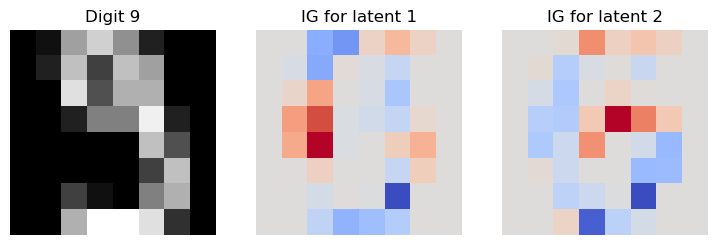

In [30]:
# Inspect a validation example and signed attribution for each coordinate.
i = 0
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(X_train[i].reshape(8,8), cmap='gray')
axes[0].set_title(f'Digit {y_train[i]}')
limit = np.abs(encoder_ig_train[i]).max()
for j in range(2):
    axes[j+1].imshow(attributions[i,j].reshape(8,8), cmap='coolwarm', vmin=-limit, vmax=limit)
    axes[j+1].set_title(f'IG for latent {j+1}')
for ax in axes: ax.axis('off')
plt.show()

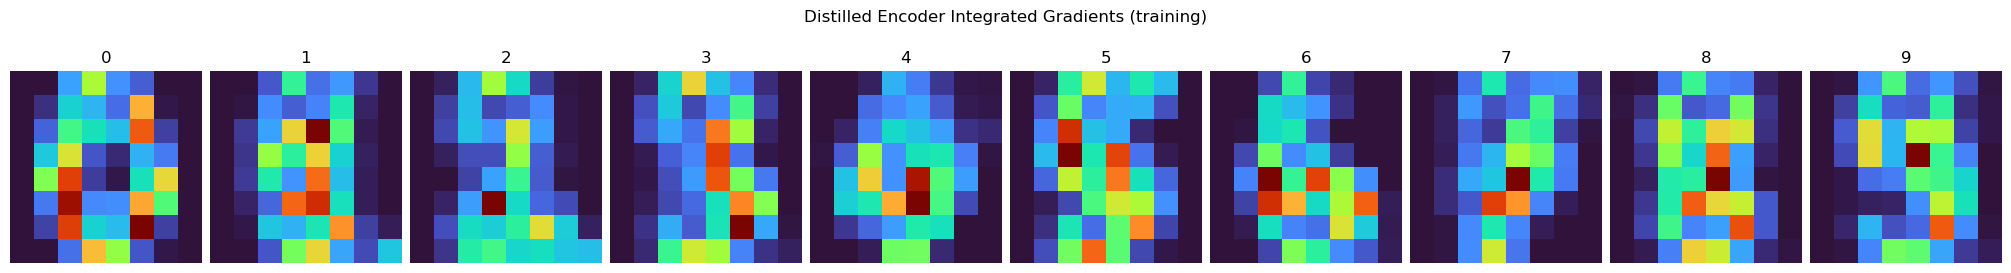

In [31]:
l2_importance = np.linalg.norm(encoder_ig_train, axis=1)
fig, axes = plt.subplots(1, 10, figsize=(20, 3), layout='constrained')
for digit, ax in enumerate(axes.flat):
    values = l2_importance[y_train == digit].mean(axis=0)
    values = values / max(values.sum(), np.finfo(float).eps)
    ax.imshow(values.reshape(8, 8), cmap='turbo', vmin=0)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('Distilled Encoder Integrated Gradients (training)')
plt.show()


### Explanation consistency

In [3]:
import numpy as np
from pathlib import Path

folder = Path("/Users/clairehe/Documents/GitHub/MEDAL_FI/encoder_FI/experiments/arch_search/comp_files")

saved = np.load(folder / "medal_vs_encoder_ig.npz")
A = saved["medal_ig"]
B = saved["encoder_ig"]

assert A.shape == B.shape and A.ndim == 3
assert np.isfinite(A).all() and np.isfinite(B).all()

def cosine_per_image(a, b):
    numerator = np.sum(a * b, axis=1)
    denominator = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    return np.divide(
        numerator, denominator,
        out=np.full(len(a), np.nan),
        where=denominator > 0,
    )

# 1. Signed IG cosine: preserves signs and latent coordinates.
signed_cosine = cosine_per_image(
    A.reshape(len(A), -1),
    B.reshape(len(B), -1),
)

# Pixel importance: L2 magnitude across latent coordinates.
A_magnitude = np.linalg.norm(A, axis=1)
B_magnitude = np.linalg.norm(B, axis=1)

# 2. Magnitude cosine: compares unsigned pixel importance.
magnitude_cosine = cosine_per_image(A_magnitude, B_magnitude)

# 3. Top-k overlap: fraction of the k most important pixels shared.
k = 10
assert 1 <= k <= A.shape[-1]

# Stable sorting makes ties deterministic.
A_topk = np.argsort(-A_magnitude, axis=1, kind="stable")[:, :k]
B_topk = np.argsort(-B_magnitude, axis=1, kind="stable")[:, :k]

topk_overlap = np.array([
    np.intersect1d(a, b).size / k
    for a, b in zip(A_topk, B_topk)
])

# Entirely zero maps have no meaningful top-k ranking.
valid = (A_magnitude.max(axis=1) > 0) & (B_magnitude.max(axis=1) > 0)
topk_overlap[~valid] = np.nan

print(f"Mean signed IG cosine: {np.nanmean(signed_cosine):.4f}")
print(f"Mean magnitude cosine: {np.nanmean(magnitude_cosine):.4f}")
print(f"Mean top-{k} overlap:   {np.nanmean(topk_overlap):.4f}")

Mean signed IG cosine: 0.3779
Mean magnitude cosine: 0.8138
Mean top-10 overlap:   0.5562


In [17]:

def explanation_metrics(A, B, k=10):
    if A.shape != B.shape or A.ndim != 3:
        raise ValueError("IG arrays must have the same (images, coordinates, pixels) shape")
    if not 1 <= k <= A.shape[-1]:
        raise ValueError("k must be between 1 and the number of pixels")
    signed = cosine_per_image(
        A.reshape(len(A), -1),
        B.reshape(len(B), -1),
    )
    a = np.linalg.norm(A, axis=1)
    b = np.linalg.norm(B, axis=1)
    magnitude = cosine_per_image(a, b)

    a_top = np.argsort(-a, axis=1, kind="stable")[:, :k]
    b_top = np.argsort(-b, axis=1, kind="stable")[:, :k]
    overlap = np.array([
        np.intersect1d(x, y).size / k
        for x, y in zip(a_top, b_top)
    ])
    overlap[(a.max(axis=1) == 0) | (b.max(axis=1) == 0)] = np.nan
    return signed, magnitude, overlap


### Uniqueness/consistency of explanations

In [13]:
from copy import deepcopy
import numpy as np
import torch
from torch import nn

class SameOutputsDifferentIG(nn.Module):
    def __init__(self, encoder, X_train, image_shape=(8, 8),
                 strength=10.0, coordinate=0):
        super().__init__()
        self.encoder = deepcopy(encoder).cpu().eval()
        self.strength = strength
        self.coordinate = coordinate

        X_train = torch.as_tensor(
            X_train, dtype=torch.float32
        ).detach().cpu()

        # Disjoint groups: alternating image columns.
        columns = torch.arange(image_shape[1])[None, :]
        mask = (columns % 2 == 0).expand(image_shape).flatten()
        a = mask.float()
        b = (~mask).float()

        projection_a = X_train @ a
        projection_b = X_train @ b

        # Required for both residual branches to saturate at every image.
        if not ((projection_a > 0).all() and (projection_b > 0).all()):
            raise ValueError(
                "Some images have no ink in one group. "
                "Choose a different pixel partition."
            )

        self.register_buffer("a", a)
        self.register_buffer("b", b)
        self.register_buffer("eps_a", projection_a.min() / 2)
        self.register_buffer("eps_b", projection_b.min() / 2)

    def forward(self, x):
        z = self.encoder(x)
        u = torch.clamp((x @ self.a) / self.eps_a, 0, 1)
        v = torch.clamp((x @ self.b) / self.eps_b, 0, 1)

        direction = torch.zeros_like(z)
        direction[:, self.coordinate] = 1
        return z + self.strength * (u - v)[:, None] * direction

    def exact_added_ig(self, x):
        """Exact residual IG for positive projections and zero baseline."""
        x = torch.as_tensor(x, dtype=self.a.dtype, device=self.a.device)
        pa, pb = x @ self.a, x @ self.b
        if not ((pa >= self.eps_a).all() and
                (pb >= self.eps_b).all()):
            raise ValueError("Both branches must saturate at these images.")

        pixel_contributions = self.strength * (
            x * self.a / pa[:, None] - x * self.b / pb[:, None]
        )

        with torch.no_grad():
            latent_dim = self.encoder(x[:1]).shape[1]

        added = x.new_zeros((len(x), latent_dim, x.shape[1]))
        added[:, self.coordinate, :] = pixel_contributions
        return added


X_cpu = torch.as_tensor(X_train, dtype=torch.float32).detach().cpu()
original = deepcopy(model.encoder).cpu().eval()

constructed = SameOutputsDifferentIG(
    original,
    X_cpu,
    image_shape=(8, 8),   # Use (28, 28) for full MNIST.
    strength=10.0,
).eval()

with torch.no_grad():
    original_outputs = original(X_cpu)
    constructed_outputs = constructed(X_cpu)

print(
    "Maximum output difference:",
    (original_outputs - constructed_outputs).abs().max().item(),
)
assert torch.equal(original_outputs, constructed_outputs)

Maximum output difference: 0.0


In [18]:
# Shape: (training images, latent coordinates, pixels).
# Reuse the original MEDAL IG; IG is additive across output branches.
added_ig = constructed.exact_added_ig(X_cpu).detach().numpy()
constructed_ig = medal_train_ig + added_ig

signed, magnitude, overlap = explanation_metrics(
    medal_train_ig, constructed_ig, k=10
)

print("Mean signed cosine:", np.nanmean(signed))
print("Mean magnitude cosine:", np.nanmean(magnitude))
print("Mean top-10 overlap:", np.nanmean(overlap))
print("Maximum added completeness residual:",
      np.abs(added_ig.sum(axis=-1)).max())

Mean signed cosine: 0.4459071612622657
Mean magnitude cosine: 0.8770317847672704
Mean top-10 overlap: 0.588076588337685
Maximum added completeness residual: 1.9073486e-06


In [20]:
df = pd.read_csv('/Users/clairehe/Documents/GitHub/MEDAL_FI/encoder_FI/experiments/arch_search/comp_files/seed_consistency/agreement_summary.csv')

In [21]:
df

,objective,signed_cosine,magnitude_cosine,top10_overlap
0,encoder_only,0.199196,0.784452,0.512472
1,medal,0.217223,0.784710,0.516887


### Explanations of poorly reconstructed Baby MNIST samples

This analysis reloads the saved **validation** explanations and MEDAL checkpoint; no training or attribution computation is required. An encoder-only model has no reconstruction error of its own: both explanation sets are stratified using **MEDAL's** per-image reconstruction MSE. The upper and lower error quartiles define poorly and well reconstructed groups. These are diagnostics of the fitted autoencoder, not labels of teacher fidelity or explanation correctness. The two latent-coordinate explanations use different positive global output scales; signed/magnitude cosine and pixel rankings are invariant to this scaling, and coordinate plots below convert encoder-only IG to MEDAL's scale.

In [32]:
from pathlib import Path
from copy import deepcopy
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from medal.io import load_model
from sklearn.datasets import load_digits

poor_base = Path('/Users/clairehe/Documents/GitHub/MEDAL_FI')
poor_out = poor_base / 'data/baby_mnist_medal'
poor_source = poor_base / 'encoder_FI/experiments/arch_search'
poor_cfg = json.loads((poor_out / 'config.json').read_text())
poor_model = load_model(
    poor_out / 'baby_mnist_ckpts/final.pt', input_dim=64,
    hidden_dims=tuple(poor_cfg['hidden_dims']), latent_dim=2,
    activation=poor_cfg['activation'], use_batchnorm=poor_cfg['use_batchnorm'],
    dropout_rate=poor_cfg['dropout_rate'],
).cpu().eval()
with np.load(poor_source / 'comp_files/medal_vs_encoder_ig.npz') as saved:
    poor_medal_ig = saved['medal_ig'].copy()
    poor_encoder_ig = saved['encoder_ig'].copy()
    poor_medal_delta = saved['medal_delta'].copy()
    poor_encoder_delta = saved['encoder_delta'].copy()
poor_X = np.load(poor_source / 'X_val.npy').astype(np.float32)
# The paired IG file does not store validation inputs/labels. Cross-check
# its intended input order against the separately saved validation archive.
with np.load(poor_out / 'encoder_ig.npz') as saved:
    np.testing.assert_array_equal(poor_X, saved['X'])
    poor_labels = saved['labels'].astype(int)
assert poor_medal_ig.shape == poor_encoder_ig.shape == (len(poor_X), 2, 64)
assert len(poor_labels) == len(poor_X)
assert np.isfinite(poor_medal_ig).all() and np.isfinite(poor_encoder_ig).all()
with np.load(poor_out / 'teacher_normalization.npz') as saved:
    poor_scale = float(saved['scale'])
poor_encoder_ig_normalized = poor_encoder_ig / poor_scale
poor_encoder = deepcopy(poor_model.encoder)
poor_encoder.load_state_dict(torch.load(
    poor_source / 'comp_files/encoder_only.pt', map_location='cpu', weights_only=True,
))
poor_encoder.eval()
with torch.no_grad():
    poor_reconstruction, poor_z = poor_model(torch.from_numpy(poor_X))
    poor_encoder_z_raw = poor_encoder(torch.from_numpy(poor_X)).numpy()
with np.load(poor_out / 'teacher_normalization.npz') as saved:
    poor_encoder_z = (poor_encoder_z_raw - saved['mean']) / poor_scale
poor_reconstruction = poor_reconstruction.numpy()
poor_recon_mse = np.mean((poor_X - poor_reconstruction)**2, axis=1)
poor_pair_mse = np.mean((poor_z.numpy() - poor_encoder_z)**2, axis=1)
poor_train_mean = np.load(poor_source / 'X_train.npy').mean(axis=0)
poor_baseline_mse = np.mean((poor_X - poor_train_mean)**2, axis=1)
poor_low, poor_high = np.quantile(poor_recon_mse, [0.25, 0.75])
poor_group = np.full(len(poor_X), 'middle', dtype=object)
poor_group[poor_recon_mse <= poor_low] = 'well reconstructed'
poor_group[poor_recon_mse >= poor_high] = 'poorly reconstructed'
print(f'Validation images: {len(poor_X)}; MSE quartiles: {poor_low:.3f}, {poor_high:.3f}')

Validation images: 288; MSE quartiles: 4.352, 9.503


,n_images,reconstruction_mse,baseline_mse,student_pair_mse,signed_cosine,magnitude_cosine,top10_overlap,medal_abs_ig_delta,encoder_abs_ig_delta
group,,,,,,,,,
middle,144,6.381808,18.081717,0.002926,0.375793,0.816103,0.559722,0.000535,0.000036
poorly reconstructed,72,15.868160,20.343779,0.013874,0.425098,0.821458,0.572222,0.000506,0.000035
well reconstructed,72,3.248790,18.874896,0.000946,0.334847,0.801675,0.533333,0.000582,0.000036


group,middle,poorly reconstructed,well reconstructed
digit,,,
0,13,3,11
1,10,6,9
2,19,7,5
3,13,4,4
4,14,11,12
5,21,8,4
6,13,3,14
7,12,10,10
8,16,9,0


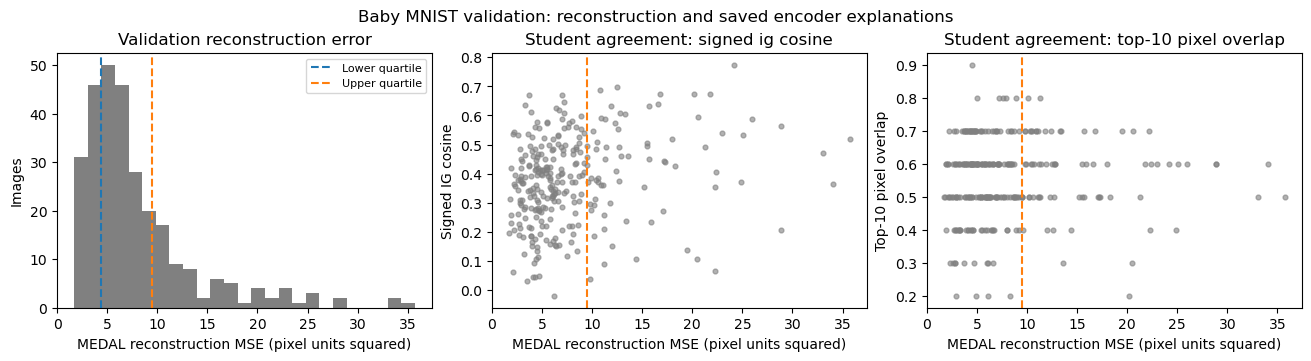

In [33]:
def poor_cosine(a, b):
    denominator = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    return np.divide((a*b).sum(axis=1), denominator,
                     out=np.full(len(a), np.nan), where=denominator > 0)

poor_medal_maps = np.linalg.norm(poor_medal_ig, axis=1)
poor_encoder_maps = np.linalg.norm(poor_encoder_ig_normalized, axis=1)
poor_signed = poor_cosine(poor_medal_ig.reshape(len(poor_X), -1),
                          poor_encoder_ig_normalized.reshape(len(poor_X), -1))
poor_magnitude = poor_cosine(poor_medal_maps, poor_encoder_maps)
poor_topk = 10
poor_top_m = np.argsort(-poor_medal_maps, axis=1, kind='stable')[:, :poor_topk]
poor_top_e = np.argsort(-poor_encoder_maps, axis=1, kind='stable')[:, :poor_topk]
poor_overlap = np.array([np.intersect1d(a,b).size / poor_topk
                         for a,b in zip(poor_top_m, poor_top_e)])
poor_overlap[(poor_medal_maps.max(axis=1)==0) | (poor_encoder_maps.max(axis=1)==0)] = np.nan
poor_table = pd.DataFrame({
    'validation_row': np.arange(len(poor_X)), 'digit': poor_labels,
    'group': poor_group, 'reconstruction_mse': poor_recon_mse,
    'mean_image_baseline_mse': poor_baseline_mse,
    'student_pair_mse': poor_pair_mse, 'signed_cosine': poor_signed,
    'magnitude_cosine': poor_magnitude, 'top10_overlap': poor_overlap,
    'medal_mean_abs_ig_delta': np.abs(poor_medal_delta).mean(axis=1),
    'encoder_mean_abs_ig_delta_normalized': np.abs(poor_encoder_delta).mean(axis=1) / poor_scale,
})
poor_summary = poor_table.groupby('group').agg(
    n_images=('validation_row', 'size'), reconstruction_mse=('reconstruction_mse', 'mean'),
    baseline_mse=('mean_image_baseline_mse', 'mean'), student_pair_mse=('student_pair_mse', 'mean'),
    signed_cosine=('signed_cosine', 'mean'), magnitude_cosine=('magnitude_cosine', 'mean'),
    top10_overlap=('top10_overlap', 'mean'),
    medal_abs_ig_delta=('medal_mean_abs_ig_delta', 'mean'),
    encoder_abs_ig_delta=('encoder_mean_abs_ig_delta_normalized', 'mean'),
)
from IPython.display import display
display(poor_summary)
display(pd.crosstab(poor_table['digit'], poor_table['group']))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
axes[0].hist(poor_recon_mse, bins=25, color='0.5')
axes[0].axvline(poor_low, color='tab:blue', linestyle='--', label='Lower quartile')
axes[0].axvline(poor_high, color='tab:orange', linestyle='--', label='Upper quartile')
axes[0].set(xlabel='MEDAL reconstruction MSE (pixel units squared)', ylabel='Images', title='Validation reconstruction error')
axes[0].legend(fontsize=8)
for ax, values, label in zip(axes[1:], [poor_signed, poor_overlap], ['Signed IG cosine', 'Top-10 pixel overlap']):
    ax.scatter(poor_recon_mse, values, c='0.5', s=12, alpha=0.6)
    ax.axvline(poor_high, color='tab:orange', linestyle='--')
    ax.set(xlabel='MEDAL reconstruction MSE (pixel units squared)', ylabel=label,
           title=f'Student agreement: {label.lower()}')
fig.suptitle('Baby MNIST validation: reconstruction and saved encoder explanations')
plt.show()

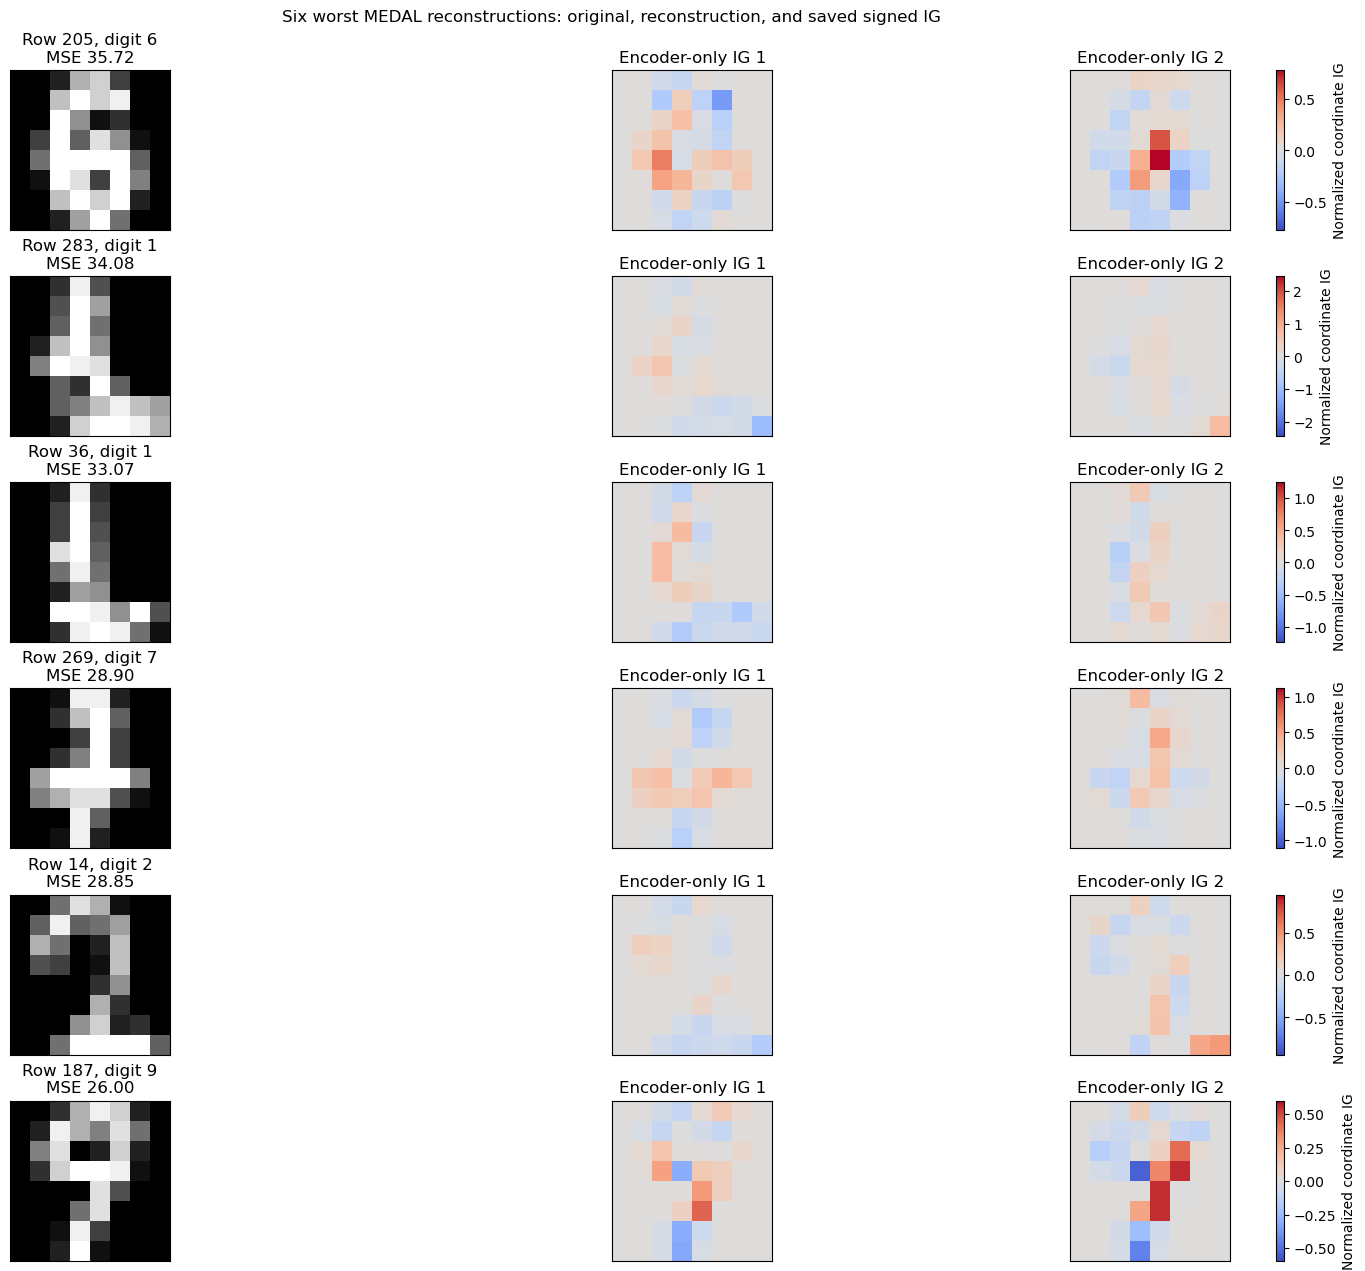

,validation_row,digit,group,reconstruction_mse,mean_image_baseline_mse,student_pair_mse,signed_cosine,magnitude_cosine,top10_overlap,medal_mean_abs_ig_delta,encoder_mean_abs_ig_delta_normalized
205,205,6,poorly reconstructed,35.715832,14.185363,0.114352,0.520000,0.849249,0.5,0.001152,0.000045
283,283,1,poorly reconstructed,34.082783,22.709501,0.046955,0.363448,0.868053,0.6,0.000344,0.000034
36,36,1,poorly reconstructed,33.067066,21.062348,0.013989,0.471755,0.805774,0.5,0.000351,0.000096
269,269,7,poorly reconstructed,28.896194,20.052067,0.003898,0.563607,0.815135,0.6,0.000445,0.000014
14,14,2,poorly reconstructed,28.851761,20.839491,0.042735,0.207689,0.907518,0.6,0.000368,0.000035
187,187,9,poorly reconstructed,26.002285,18.973602,0.001151,0.589355,0.796005,0.6,0.000246,0.000037


In [49]:
# The worst images, with signed IG on a shared normalized scale per row.
poor_worst = np.argsort(-poor_recon_mse, kind='stable')[:6]
fig, axes = plt.subplots(len(poor_worst), 3, figsize=(15, 2.1*len(poor_worst)), squeeze=False,
                         layout='constrained')
for row, idx in enumerate(poor_worst):
    image = poor_X[idx].reshape(8,8)
    recon = poor_reconstruction[idx].reshape(8,8)
    error = np.abs(image-recon)
    axes[row,0].imshow(image, cmap='gray', vmin=0, vmax=16)
    axes[row,0].set_title(f'Row {idx}, digit {poor_labels[idx]}\nMSE {poor_recon_mse[idx]:.2f}')
    # axes[row,1].imshow(recon, cmap='gray', vmin=0, vmax=16)
    # axes[row,1].set_title('MEDAL reconstruction')
    # error_plot = axes[row,2].imshow(error, cmap='magma', vmin=0, vmax=max(error.max(), 1e-12))
    # axes[row,2].set_title('Absolute pixel error')
    # fig.colorbar(error_plot, ax=axes[row,2], fraction=.05, label='Pixel units')
    limit = max(np.abs(poor_medal_ig[idx]).max(), np.abs(poor_encoder_ig_normalized[idx]).max(), 1e-12)
    for coord in range(2):
        for offset, attrs, name in [(1, poor_encoder_ig_normalized, 'Encoder-only')]:# , (5, poor_encoder_ig_normalized, 'Encoder-only')]:
            ax = axes[row,offset+coord]
            im = ax.imshow(attrs[idx,coord].reshape(8,8), cmap='coolwarm', vmin=-limit, vmax=limit)
            ax.set_title(f'{name} IG {coord+1}')
    fig.colorbar(im, ax=list(axes[row,1:]), fraction=.015, label='Normalized coordinate IG')
    for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Six worst MEDAL reconstructions: original, reconstruction, and saved signed IG')
plt.show()
display(poor_table.iloc[poor_worst])

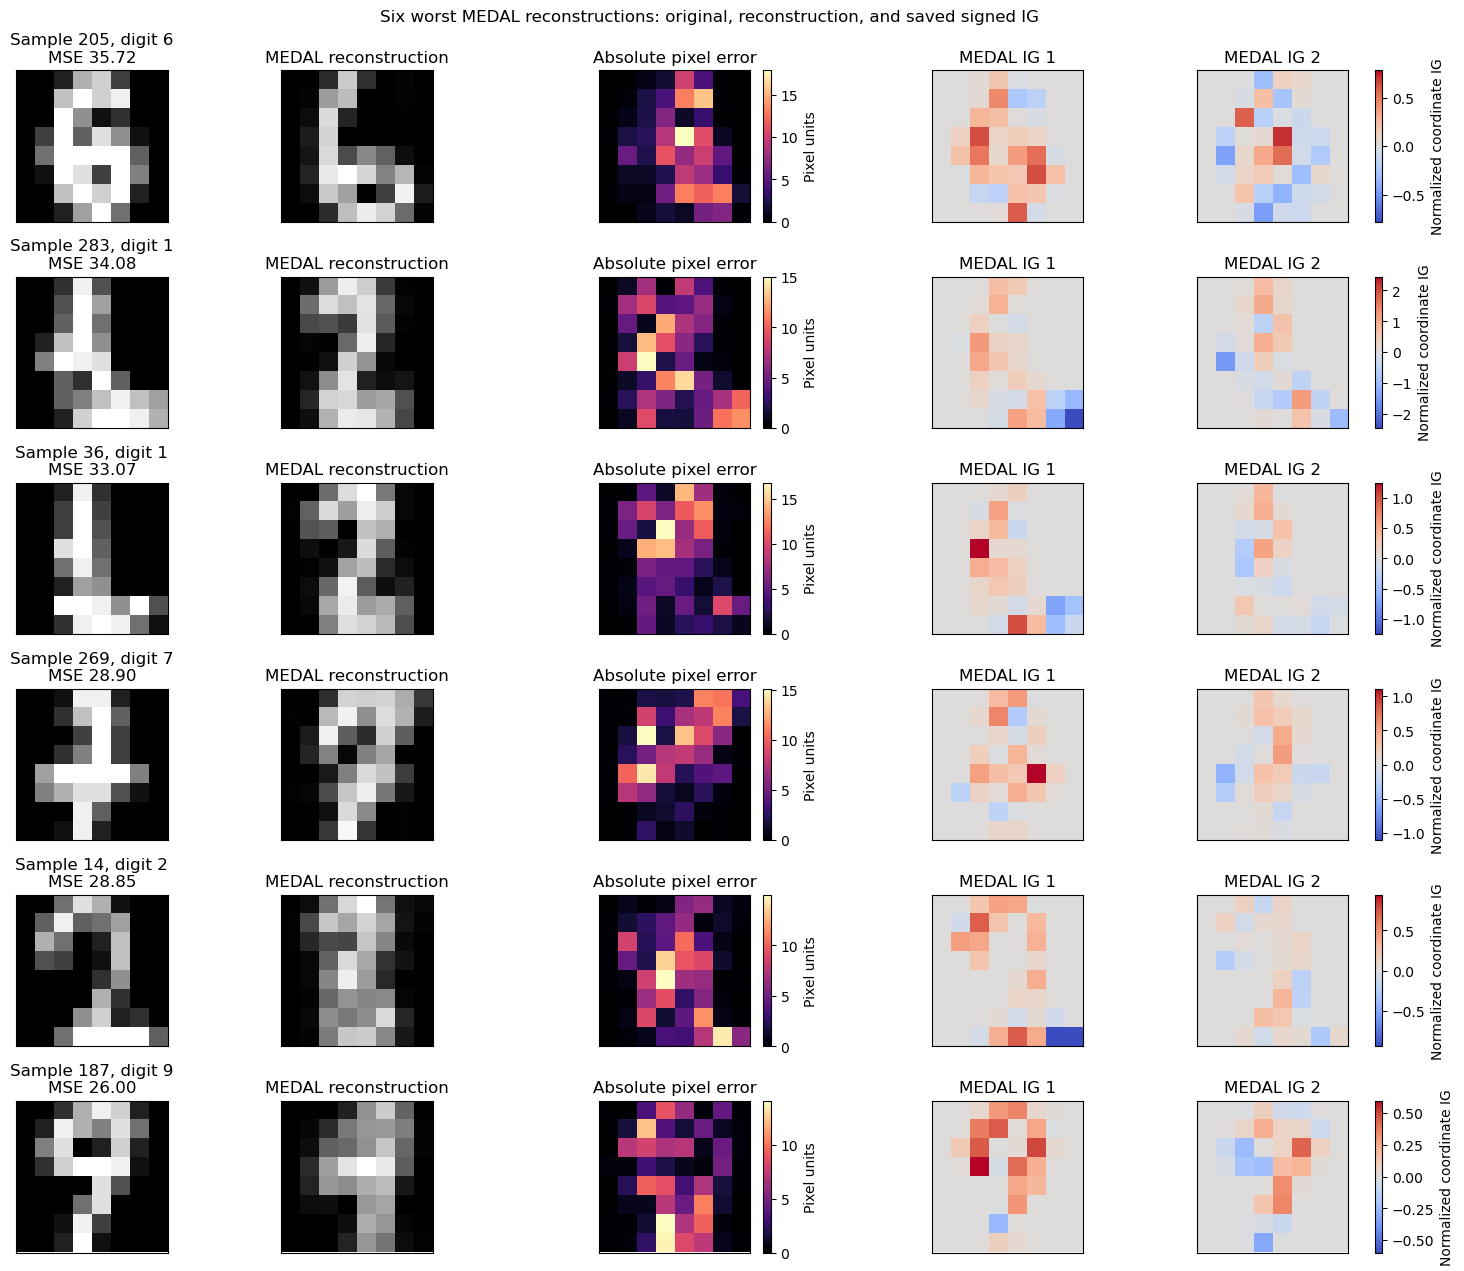

,validation_row,digit,group,reconstruction_mse,mean_image_baseline_mse,student_pair_mse,signed_cosine,magnitude_cosine,top10_overlap,medal_mean_abs_ig_delta,encoder_mean_abs_ig_delta_normalized
205,205,6,poorly reconstructed,35.715832,14.185363,0.114352,0.520000,0.849249,0.5,0.001152,0.000045
283,283,1,poorly reconstructed,34.082783,22.709501,0.046955,0.363448,0.868053,0.6,0.000344,0.000034
36,36,1,poorly reconstructed,33.067066,21.062348,0.013989,0.471755,0.805774,0.5,0.000351,0.000096
269,269,7,poorly reconstructed,28.896194,20.052067,0.003898,0.563607,0.815135,0.6,0.000445,0.000014
14,14,2,poorly reconstructed,28.851761,20.839491,0.042735,0.207689,0.907518,0.6,0.000368,0.000035
187,187,9,poorly reconstructed,26.002285,18.973602,0.001151,0.589355,0.796005,0.6,0.000246,0.000037


In [69]:
# The worst images, with signed IG on a shared normalized scale per row.
poor_worst = np.argsort(-poor_recon_mse, kind='stable')[:6]
fig, axes = plt.subplots(len(poor_worst), 5, figsize=(15, 2.1*len(poor_worst)), squeeze=False,
                         layout='constrained')
for row, idx in enumerate(poor_worst):
    image = poor_X[idx].reshape(8,8)
    recon = poor_reconstruction[idx].reshape(8,8)
    error = np.abs(image-recon)
    axes[row,0].imshow(image, cmap='gray', vmin=0, vmax=16)
    axes[row,0].set_title(f'Sample {idx}, digit {poor_labels[idx]}\nMSE {poor_recon_mse[idx]:.2f}')
    axes[row,1].imshow(recon, cmap='gray', vmin=0, vmax=16)
    axes[row,1].set_title('MEDAL reconstruction')
    error_plot = axes[row,2].imshow(error, cmap='magma', vmin=0, vmax=max(error.max(), 1e-12))
    axes[row,2].set_title('Absolute pixel error')
    fig.colorbar(error_plot, ax=axes[row,2], fraction=.05, label='Pixel units')
    limit = max(np.abs(poor_medal_ig[idx]).max(), np.abs(poor_encoder_ig_normalized[idx]).max(), 1e-12)
    for coord in range(2):
        for offset, attrs, name in [(3, poor_medal_ig, 'MEDAL')]:
            ax = axes[row,offset+coord]
            im = ax.imshow(attrs[idx,coord].reshape(8,8), cmap='coolwarm', vmin=-limit, vmax=limit)
            ax.set_title(f'{name} IG {coord+1}')
    fig.colorbar(im, ax=list(axes[row,3:]), fraction=.015, label='Normalized coordinate IG')
    for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Six worst MEDAL reconstructions: original, reconstruction, and saved signed IG')
plt.show()
display(poor_table.iloc[poor_worst])

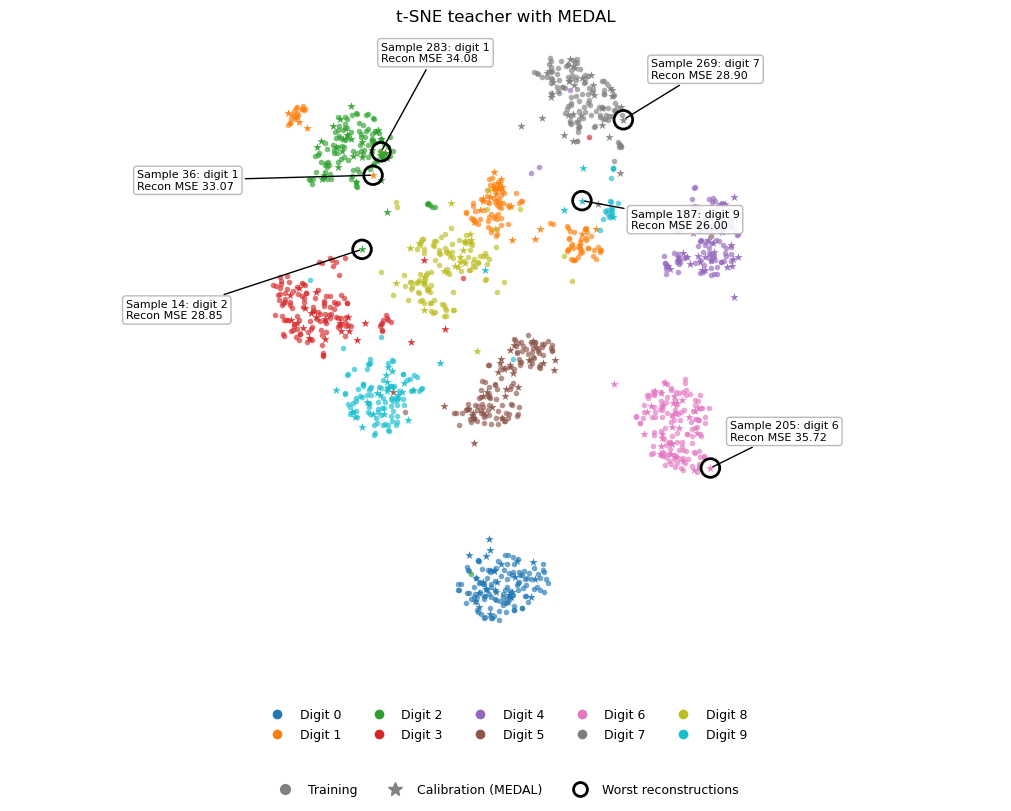

In [68]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 8), layout='constrained')
poor_digit_cmap = plt.get_cmap('tab10')

for digit in range(10):
    mask_train = poor_teacher_labels == digit
    mask_cal = poor_val_labels == digit
    color = poor_digit_cmap(digit)

    # Training: circles
    ax.scatter(
        poor_teacher_train[mask_train, 0],
        poor_teacher_train[mask_train, 1],
        s=16, alpha=0.65, color=color,
        linewidths=0, marker='o'
    )

    # Calibration: stars
    ax.scatter(
        poor_predicted_raw[mask_cal, 0],
        poor_predicted_raw[mask_cal, 1],
        s=40, alpha=0.9, color=color,
        linewidths=0, marker='*'
    )

# Highlight six worst calibration reconstructions
ax.scatter(
    poor_predicted_raw[poor_worst, 0],
    poor_predicted_raw[poor_worst, 1],
    s=180, facecolors='none', edgecolors='black',
    linewidths=2, zorder=5
)

poor_offsets = [(14, 20), (0, 65), (-170, -10),
                (20, 30), (-170, -50), (35, -20)]

for idx, offset in zip(poor_worst, poor_offsets):
    ax.annotate(
        f'Sample {idx}: digit {poor_val_labels[idx]}\n'
        f'Recon MSE {poor_recon_mse[idx]:.2f}',
        xy=poor_predicted_raw[idx],
        xytext=offset,
        textcoords='offset points',
        fontsize=8,
        bbox=dict(boxstyle='round,pad=0.3',
                  fc='white', ec='0.7', alpha=0.9),
        arrowprops=dict(arrowstyle='-', color='black'),
        zorder=6
    )

# Legend 1: Digit colors
digit_handles = [
    Line2D([0], [0], marker='o', linestyle='None',
           markerfacecolor=poor_digit_cmap(d),
           markeredgecolor='none',
           markersize=7, label=f'Digit {d}')
    for d in range(10)
]

legend_digits = ax.legend(
    handles=digit_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.08),
    ncol=5, fontsize=9, frameon=False
)
ax.add_artist(legend_digits)

# Legend 2: Dataset / marker type
type_handles = [
    Line2D([0], [0], marker='o', linestyle='None',
           color='gray', markersize=7, label='Training'),
    Line2D([0], [0], marker='*', linestyle='None',
           color='gray', markersize=10, label='Calibration (MEDAL)'),
    Line2D([0], [0], marker='o', linestyle='None',
           markerfacecolor='none', markeredgecolor='black',
           markersize=10, markeredgewidth=2,
           label='Worst reconstructions')
]

ax.legend(
    handles=type_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.20),
    ncol=3, fontsize=9, frameon=False
)

ax.set_title('t-SNE teacher with MEDAL')
ax.set_aspect('equal', adjustable='datalim')
ax.axis('off')
fig.savefig('./figures/bad_samples_scatter.pdf')


plt.show()

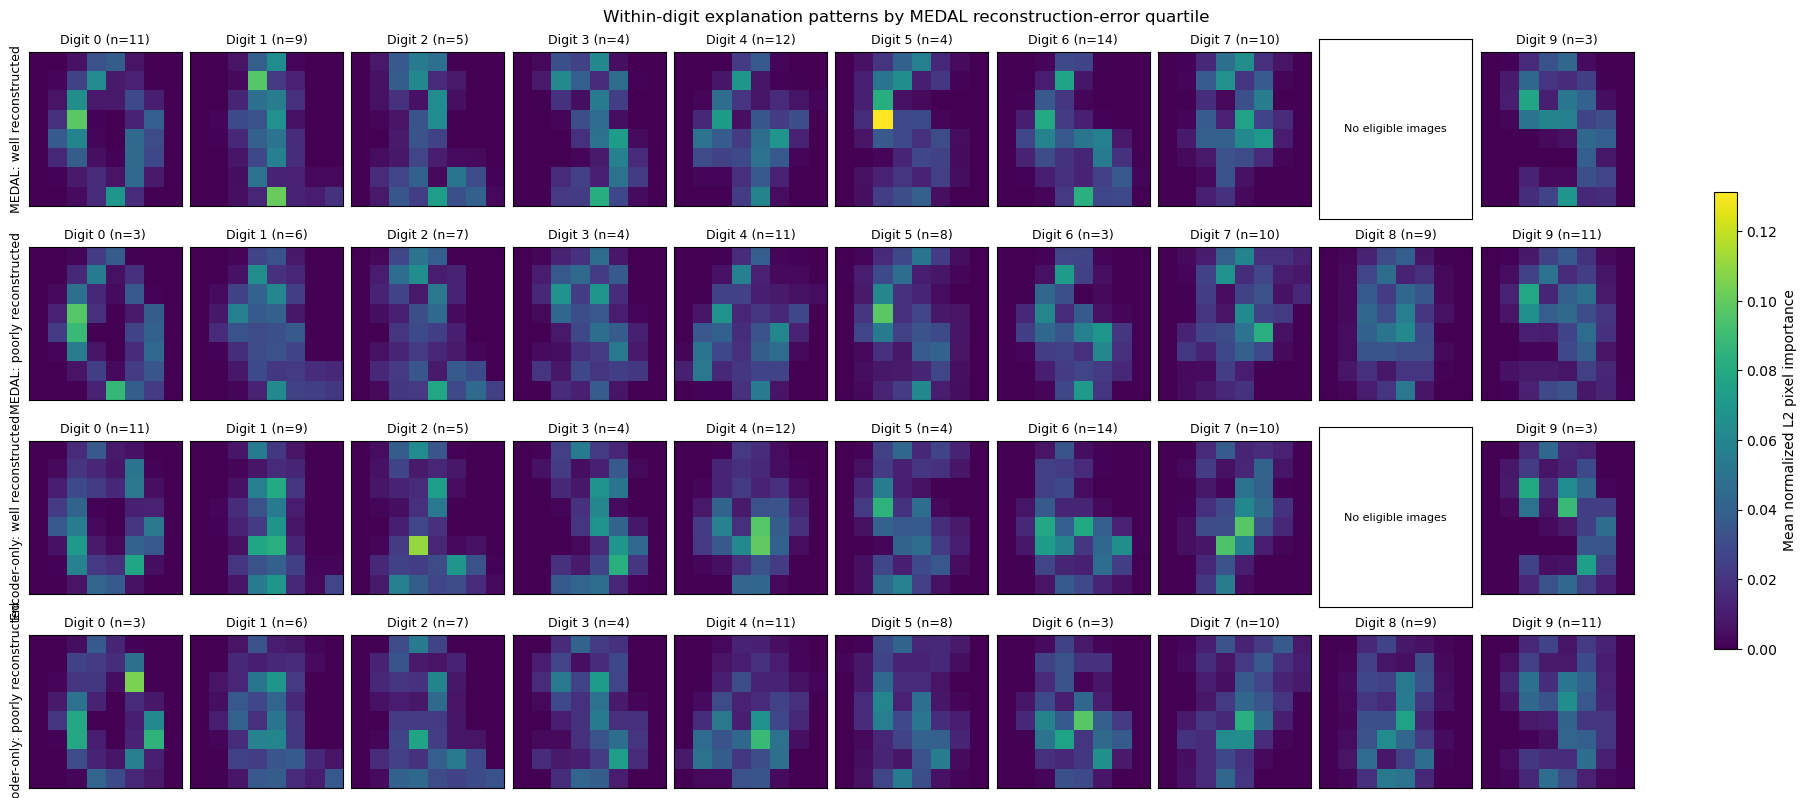

In [35]:
# Compare global maps within each digit to reduce class-composition confounding.
# Normalize each image's L2 pixel map to sum to one before averaging.
def poor_normalized_maps(values):
    total = values.sum(axis=1, keepdims=True)
    return np.divide(values, total, out=np.zeros_like(values), where=total>0)

poor_norm_m = poor_normalized_maps(poor_medal_maps)
poor_norm_e = poor_normalized_maps(poor_encoder_maps)
poor_panels = [
    ('MEDAL: well reconstructed', poor_norm_m, 'well reconstructed'),
    ('MEDAL: poorly reconstructed', poor_norm_m, 'poorly reconstructed'),
    ('Encoder-only: well reconstructed', poor_norm_e, 'well reconstructed'),
    ('Encoder-only: poorly reconstructed', poor_norm_e, 'poorly reconstructed'),
]
poor_digit_maps = {}
for row, (_, maps, group) in enumerate(poor_panels):
    for digit in range(10):
        mask = (poor_labels==digit) & (poor_group==group) & (maps.sum(axis=1)>0)
        if mask.any(): poor_digit_maps[row,digit] = (maps[mask].mean(axis=0), int(mask.sum()))
poor_map_limit = max(values.max() for values, count in poor_digit_maps.values())
fig, axes = plt.subplots(4, 10, figsize=(18, 8), layout='constrained')
for row, (title, _, _) in enumerate(poor_panels):
    for digit in range(10):
        ax = axes[row,digit]
        if (row,digit) in poor_digit_maps:
            values, count = poor_digit_maps[row,digit]
            im = ax.imshow(values.reshape(8,8), cmap='viridis', vmin=0, vmax=poor_map_limit)
            ax.set_title(f'Digit {digit} (n={count})', fontsize=9)
        else:
            ax.text(.5,.5,'No eligible images', ha='center', va='center', fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        if digit==0: ax.set_ylabel(title, fontsize=9)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.6, label='Mean normalized L2 pixel importance')
fig.suptitle('Within-digit explanation patterns by MEDAL reconstruction-error quartile')
plt.show()

**Interpretation.** Differences between groups show associations with MEDAL reconstruction performance, not explanation accuracy. Digit counts and within-digit maps help identify class-composition effects. The coordinate maps explain each encoder, not the reconstruction residual; IG completeness errors are numerical diagnostics. Student-pair MSE measures agreement between the students, not validation teacher fidelity (held-out teacher coordinates are unavailable).

## Full MNIST data


In [43]:
from pathlib import Path
import numpy as np

folder = Path(
    "/Users/clairehe/Documents/GitHub/iicd_MEDAL_feat/outputs/mnist_medal"
)

data = np.load(folder / "data.npz")
X_train = data["X_train"]
y_train = data["y_train"]
teacher_embedding = np.load(folder / "teacher_raw.npy")

X_val = data["X_val"]
y_val = data["y_val"]